## **Atividade Prática Análise Exploratória de Dados**


**Busque responder às questões a seguir:**

Insights sobre os acidentes: O que os gráficos mostram? Quais são os tipos de acidentes mais comuns? Quais são as principais causas?

Tendências temporais: Existe uma tendência de aumento ou diminuição de acidentes ao longo dos anos?

Fatores geográficos: Quais regiões têm mais acidentes?


Utilizando-se a base de dados Acidentes no Espaço Aéreo Brasileiro (Cenipa) realize:

# 1)	Importação das bibliotecas necessárias

In [128]:
import pandas as pd
import numpy as np
import seaborn as sns

# 2)	Carregamento do conjunto de dados

In [129]:
df = pd.read_csv('/content/drive/MyDrive/ColabNotebooks/Mackenzie/4Semestre/AnaliseDeDados/Aula5/Cenipa.csv', sep=';', encoding='utf-8')

# usar encoding para formatar o csv e arrumar o erro.
# a base de dados é brasileira

# não salvar o csv como .xlsx para não ter problemas no futuro ao gerar o modelo preditivo!

# 3)	Visualização das primeiras e últimas linhas do conjunto de dados

In [130]:
print(df.head())

   Codigo da Ocorrencia Classificacao da Ocorrencia   \
0                 39115                     ACIDENTE   
1                 39156              INCIDENTE GRAVE   
2                 39235                     ACIDENTE   
3                 39275                     ACIDENTE   
4                 39316                     ACIDENTE   

  Data e Hora da Ocorrencia Latitude da Ocorrencia Longitude da Ocorrencia  \
0          07/02/2010 17:40              -1,34E+11               -4,46E+11   
1          10/01/2010 23:15              -1,52E+11               -5,94E+11   
2          06/02/2010 17:20              -1,81E+11               -5,01E+11   
3          10/02/2010 09:03              -2,36E+11               -4,67E+11   
4          04/02/2010 17:55              -2,72E+11               -4,98E+11   

  Cidade da Ocorrencia UF da Ocorrencia Pais da Ocorrencia  \
0           CORRENTINA               BA             BRASIL   
1             CASCAVEL               PR             BRASIL   
2       

In [131]:
print(df.tail())

      Codigo da Ocorrencia Classificacao da Ocorrencia   \
6109                 80249                    INCIDENTE   
6110                 80251                    INCIDENTE   
6111                 80257                     ACIDENTE   
6112                 80258                     ACIDENTE   
6113                 80259                    INCIDENTE   

     Data e Hora da Ocorrencia Latitude da Ocorrencia Longitude da Ocorrencia  \
6109          14/08/2021 15:40              -3,04E+12               -6,01E+12   
6110          17/08/2021 15:45              -1,38E+12               -4,85E+12   
6111          18/08/2021 16:00              -15430833               -54699722   
6112          16/10/2019 14:30              -14661944               -57443611   
6113          18/08/2021 12:45              -2,30E+12               -4,71E+12   

     Cidade da Ocorrencia UF da Ocorrencia Pais da Ocorrencia  \
6109               MANAUS               AM             BRASIL   
6110                BELÉM   

In [132]:
df.head()

,Codigo da Ocorrencia,Classificacao da Ocorrencia,Data e Hora da Ocorrencia,Latitude da Ocorrencia,Longitude da Ocorrencia,Cidade da Ocorrencia,UF da Ocorrencia,Pais da Ocorrencia,Aerodromo da Ocorrencia,Investigacao da Aeronave foi Liberada,...,Fator do Acidente,Aspecto do Fator da Ocorrencia,Fator Condicionante,Area do Fator,Numero da Recomendacao,Dia da Assinatura de Recomendacao,Dia do Encaminhamento da Recomendacao,Conteudo da Recomendacao,Status da Recomendacao,Orgao de Recomendacao
0,39115,ACIDENTE,07/02/2010 17:40,"-1,34E+11","-4,46E+11",CORRENTINA,BA,BRASIL,SNTY,SIM,...,APLICAÇÃO DE COMANDOS,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL,095/2011,21/07/2011,01/08/2011 00:00,Revisar os requisitos de experiência recente p...,NÃO CUMPRIDA,ANAC
1,39156,INCIDENTE GRAVE,10/01/2010 23:15,"-1,52E+11","-5,94E+11",CASCAVEL,PR,BRASIL,SBCA,SIM,...,MANUTENÇÃO DA AERONAVE,DESEMPENHO DO SER HUMANO,MANUTENÇÃO DA AERONAVE,FATOR OPERACIONAL,063/2011,30/06/2011,01/08/2011 00:00,Divulgar este Relatório aos operadores de aero...,CUMPRIDA,ANAC
2,39235,ACIDENTE,06/02/2010 17:20,"-1,81E+11","-5,01E+11",ITUMBIARA,GO,BRASIL,****,SIM,...,PLANEJAMENTO DE VOO,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL,205/2011,29/08/2011,29/09/2011 00:00,Realizar uma vistoria de segurança de voo na A...,CUMPRIDA,ANAC
3,39275,ACIDENTE,10/02/2010 09:03,"-2,36E+11","-4,67E+11",SÃO PAULO,SP,BRASIL,****,SIM,...,APLICAÇÃO DE COMANDOS,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL,A-009/CENIPA/2014 – 01,22/04/2016,17/05/2016 00:00,Avaliar a necessidade de criar um regulamento ...,NÃO CUMPRIDA,ANAC
4,39316,ACIDENTE,04/02/2010 17:55,"-2,72E+11","-4,98E+11",RIO DO OESTE,SC,BRASIL,****,SIM,...,CONDIÇÕES METEOROLÓGICAS ADVERSAS,ELEMENTOS RELACIONADOS AO AMBIENTE OPERACIONAL,***,FATOR OPERACIONAL,034/2011,18/05/2011,27/05/2011 00:00,Realizar uma auditoria no Aeroclube de Blumena...,CUMPRIDA,ANAC


# 4)	Análise das informações do conjunto de dados

In [133]:
df.shape
# o nosso dataset tem 6114 linhas e 52 colunas!

(6114, 52)

In [134]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6114 entries, 0 to 6113
Data columns (total 52 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Codigo da Ocorrencia                     6114 non-null   int64  
 1   Classificacao da Ocorrencia              6114 non-null   object 
 2   Data e Hora da Ocorrencia                6114 non-null   object 
 3   Latitude da Ocorrencia                   4552 non-null   object 
 4   Longitude da Ocorrencia                  4552 non-null   object 
 5   Cidade da Ocorrencia                     6114 non-null   object 
 6   UF da Ocorrencia                         6114 non-null   object 
 7   Pais da Ocorrencia                       6114 non-null   object 
 8   Aerodromo da Ocorrencia                  6114 non-null   object 
 9   Investigacao da Aeronave foi Liberada    5827 non-null   object 
 10  Status da Investigacao                   5773 no

In [135]:
df.dtypes

,0
Codigo da Ocorrencia,int64
Classificacao da Ocorrencia,object
Data e Hora da Ocorrencia,object
Latitude da Ocorrencia,object
Longitude da Ocorrencia,object
Cidade da Ocorrencia,object
UF da Ocorrencia,object
Pais da Ocorrencia,object
Aerodromo da Ocorrencia,object
Investigacao da Aeronave foi Liberada,object


In [136]:
df.duplicated().sum()
# temos 0 valores de linhas duplicadas!

np.int64(0)

In [137]:
df.describe()

,Codigo da Ocorrencia,Total de Recomendacoes,Total de Aeronaves Envolvidas,Aeronave PMD,Categoria PMD Aeronave,Quantidade de Assentos na Aeronave,Ano de Fabricacao da Aeronave,Total de Fatalidades no Acidente
count,6114.000000,6114.000000,6114.000000,6114.000000,6114.000000,5937.000000,5932.000000,6114.000000
mean,59775.058063,0.307164,1.012103,15425.669611,15425.669611,28.521475,1892.310688,0.148839
std,14552.373693,1.143202,0.113756,35377.675739,35377.675739,55.568951,452.206983,0.678303
min,39115.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,46586.250000,0.000000,1.000000,1157.000000,1157.000000,2.000000,1978.000000,0.000000
50%,53110.500000,0.000000,1.000000,2073.000000,2073.000000,6.000000,1992.000000,0.000000
75%,78142.500000,0.000000,1.000000,6226.500000,6226.500000,10.000000,2008.000000,0.000000
max,80259.000000,23.000000,3.000000,396895.000000,396895.000000,384.000000,9999.000000,16.000000


OBS.: Fazer um dicionário de dados!!!

# Criando um dicionário para os dados

In [138]:
columns_list = df.columns.tolist()
print(columns_list)

['Codigo da Ocorrencia', 'Classificacao da Ocorrencia ', 'Data e Hora da Ocorrencia', 'Latitude da Ocorrencia', 'Longitude da Ocorrencia', 'Cidade da Ocorrencia', 'UF da Ocorrencia', 'Pais da Ocorrencia', 'Aerodromo da Ocorrencia', 'Investigacao da Aeronave foi Liberada', 'Status da Investigacao', 'Numero do Relatorio de Divulgacao', 'Relatorio de  Divulgacao foi Publicado?', 'Dia da Divulgacao da Publicacao', 'Total de Recomendacoes', 'Total de Aeronaves Envolvidas', 'Ocorrencia na Saida da Pista?', 'Tipo de Ocorrencia', 'Tipo de Categoria da Ocorrencia', 'Taxonomia do Tipo de Icao', 'Matricula da Aeronave', 'Categoria do Operador de Aeronave', 'Tipo de Aeronave', 'Fabricante da Aeronave', 'Modelo de Aeronave', 'Tipo de Aeronave Icao', 'Aeronave Motor Tipo', 'Aeronave Motor Quantidade', 'Aeronave PMD', 'Categoria PMD Aeronave', 'Quantidade de Assentos na Aeronave', 'Ano de Fabricacao da Aeronave', 'Pais Fabricante da Aeronave', 'Pais de Registro da Aeronave', 'Registro da Categoria da

In [139]:
data_dictionary = pd.DataFrame(columns=['Nome', 'Tipo de Dado', 'Descricao'])

data_dictionary['Nome'] = columns_list

for column in columns_list:
  data_dictionary.loc[data_dictionary['Nome'] == column, 'Tipo de Dado'] = df[column].dtype


data_dictionary.head()

,Nome,Tipo de Dado,Descricao
0,Codigo da Ocorrencia,int64,NaN
1,Classificacao da Ocorrencia,object,NaN
2,Data e Hora da Ocorrencia,object,NaN
3,Latitude da Ocorrencia,object,NaN
4,Longitude da Ocorrencia,object,NaN


In [140]:
descricoes = {
    'Codigo da Ocorrencia': 'Identificador único da ocorrência no banco de dados do CENIPA',
    'Classificacao da Ocorrencia ': 'Gravidade da ocorrência (Ex: Acidente, Incidente Grave, Incidente)',
    'Data e Hora da Ocorrencia': 'Data e hora local em que o evento aconteceu',
    'Latitude da Ocorrencia': 'Coordenada de latitude do local da ocorrência',
    'Longitude da Ocorrencia': 'Coordenada de longitude do local da ocorrência',
    'Cidade da Ocorrencia': 'Município onde a ocorrência aconteceu',
    'UF da Ocorrencia': 'Unidade Federativa (Estado) onde a ocorrência aconteceu',
    'Pais da Ocorrencia': 'País onde a ocorrência aconteceu',
    'Aerodromo da Ocorrencia': 'Código ICAO do aeródromo relacionado à ocorrência (se aplicável)',
    'Investigacao da Aeronave foi Liberada': 'Indica se a aeronave foi liberada após os trabalhos iniciais de investigação',
    'Status da Investigacao': 'Fase atual ou status final do processo de investigação (Ex: Ativa, Finalizada)',
    'Numero do Relatorio de Divulgacao': 'Número de identificação do relatório oficial emitido',
    'Relatorio de  Divulgacao foi Publicado?': 'Indica se o relatório final de investigação já é público',
    'Dia da Divulgacao da Publicacao': 'Data em que o relatório final foi disponibilizado',
    'Total de Recomendacoes': 'Quantidade de recomendações de segurança emitidas no relatório',
    'Total de Aeronaves Envolvidas': 'Número de aeronaves que se envolveram na mesma ocorrência',
    'Ocorrencia na Saida da Pista?': 'Indica se o evento ocorreu durante uma excursão/saída não intencional de pista',
    'Tipo de Ocorrencia': 'Descrição sumária da natureza do evento (Ex: Falha do motor, Colisão, Pouso brusco)',
    'Tipo de Categoria da Ocorrencia': 'Categorização principal baseada no tipo de ocorrência',
    'Taxonomia do Tipo de Icao': 'Classificação padronizada internacionalmente pela OACI/ICAO',
    'Matricula da Aeronave': 'Registro oficial de identificação da aeronave (Ex: PR-XYZ)',
    'Categoria do Operador de Aeronave': 'Regra de operação do operador (Ex: Particular, Táxi Aéreo, Regular)',
    'Tipo de Aeronave': 'Formato ou tipo da máquina (Ex: Avião, Helicóptero, Planador)',
    'Fabricante da Aeronave': 'Nome da empresa que fabricou a aeronave',
    'Modelo de Aeronave': 'Designação do modelo comercial ou técnico da aeronave',
    'Tipo de Aeronave Icao': 'Código padronizado do modelo da aeronave segundo a OACI/ICAO',
    'Aeronave Motor Tipo': 'Tipo de propulsão (Ex: Pistão, Turboélice, Jato)',
    'Aeronave Motor Quantidade': 'Número de motores que equipam a aeronave',
    'Aeronave PMD': 'Peso Máximo de Decolagem autorizado para a aeronave (em kg)',
    'Categoria PMD Aeronave': 'Classificação de porte baseada no peso máximo de decolagem',
    'Quantidade de Assentos na Aeronave': 'Capacidade máxima de passageiros e tripulantes',
    'Ano de Fabricacao da Aeronave': 'Ano de construção da aeronave',
    'Pais Fabricante da Aeronave': 'País sede da fabricante da aeronave',
    'Pais de Registro da Aeronave': 'País onde a matrícula da aeronave está registrada',
    'Registro da Categoria da Aeronave': 'Categoria de registro da ANAC (Ex: Instrução, Privada, Experimental)',
    'Registro Segmento da Aeronave': 'Área de atuação na aviação civil (Ex: Agrícola, Comercial, Executiva)',
    'Voo de Origem do Acidente': 'Aeródromo de onde o voo partiu',
    'Voo Destino do Acidente': 'Aeródromo para onde a aeronave planejava ir',
    'Fase de Operacao da Aeronave': 'Etapa do voo em que o evento ocorreu (Ex: Decolagem, Cruzeiro, Pouso)',
    'Tipo de Operacao da Aeronave': 'Finalidade do voo no momento do acidente (Ex: Policial, Agrícola, Instrução)',
    'Nivel de Dano da Aeronave': 'Grau de avaria sofrida pela máquina (Ex: Destruída, Substancial, Leve, Nenhum)',
    'Total de Fatalidades no Acidente': 'Número de pessoas mortas em decorrência do evento',
    'Fator do Acidente': 'Fator sistêmico ou erro que contribuiu para o evento acontecer',
    'Aspecto do Fator da Ocorrencia': 'Área específica da falha (Ex: Desempenho do Ser Humano, Elemento Material)',
    'Fator Condicionante': 'Condição subjacente que levou à falha (Ex: Manutenção da Aeronave, Operação)',
    'Area do Fator': 'Grande grupo de análise (Ex: Fator Operacional, Fator Humano, Fator Material)',
    'Numero da Recomendacao': 'Identificação única de uma recomendação de segurança gerada',
    'Dia da Assinatura de Recomendacao': 'Data em que a recomendação de segurança foi oficialmente assinada',
    'Dia do Encaminhamento da Recomendacao': 'Data de envio da recomendação ao destinatário',
    'Conteudo da Recomendacao': 'Texto com as instruções de melhoria ou correções exigidas',
    'Status da Recomendacao': 'Situação do cumprimento das exigências (Ex: Cumprida, Não Cumprida)',
    'Orgao de Recomendacao': 'Instituição destinatária responsável por implementar a recomendação (Ex: ANAC)'
}

# Mapeando as descrições diretamente o data_dictionary
# A função map() buscará os valores no dicionário que correspondam à coluna 'Nome'
data_dictionary['Descricao'] = data_dictionary['Nome'].map(descricoes)

# para ficar mais fácil de encontrar alguma coluna específica, vou mudar o índice para o 'Nome'
data_dictionary.set_index('Nome', inplace=True)

# Exibe o resultado final completo
data_dictionary

,Tipo de Dado,Descricao
Nome,,
Codigo da Ocorrencia,int64,Identificador único da ocorrência no banco de ...
Classificacao da Ocorrencia,object,"Gravidade da ocorrência (Ex: Acidente, Inciden..."
Data e Hora da Ocorrencia,object,Data e hora local em que o evento aconteceu
Latitude da Ocorrencia,object,Coordenada de latitude do local da ocorrência
Longitude da Ocorrencia,object,Coordenada de longitude do local da ocorrência
Cidade da Ocorrencia,object,Município onde a ocorrência aconteceu
UF da Ocorrencia,object,Unidade Federativa (Estado) onde a ocorrência ...
Pais da Ocorrencia,object,País onde a ocorrência aconteceu
Aerodromo da Ocorrencia,object,Código ICAO do aeródromo relacionado à ocorrên...


In [141]:
# aplicando o método strip na coluna 'Nome' e salvando em DataFrame temporário
temp_data_dict_view = data_dictionary.reset_index()
temp_data_dict_view['Nome'] = temp_data_dict_view['Nome'].str.strip()

# salvando no dicionario de dados original
data_dictionary = temp_data_dict_view.set_index('Nome')
data_dictionary

,Tipo de Dado,Descricao
Nome,,
Codigo da Ocorrencia,int64,Identificador único da ocorrência no banco de ...
Classificacao da Ocorrencia,object,"Gravidade da ocorrência (Ex: Acidente, Inciden..."
Data e Hora da Ocorrencia,object,Data e hora local em que o evento aconteceu
Latitude da Ocorrencia,object,Coordenada de latitude do local da ocorrência
Longitude da Ocorrencia,object,Coordenada de longitude do local da ocorrência
Cidade da Ocorrencia,object,Município onde a ocorrência aconteceu
UF da Ocorrencia,object,Unidade Federativa (Estado) onde a ocorrência ...
Pais da Ocorrencia,object,País onde a ocorrência aconteceu
Aerodromo da Ocorrencia,object,Código ICAO do aeródromo relacionado à ocorrên...


# 5)	Verificação de dados ausentes

In [142]:
df.isnull().sum()
# temos 21 colunas com valores ausentes

,0
Codigo da Ocorrencia,0
Classificacao da Ocorrencia,0
Data e Hora da Ocorrencia,0
Latitude da Ocorrencia,1562
Longitude da Ocorrencia,1562
Cidade da Ocorrencia,0
UF da Ocorrencia,0
Pais da Ocorrencia,0
Aerodromo da Ocorrencia,0
Investigacao da Aeronave foi Liberada,287


In [143]:
df.shape
# lembrando que temos 6114 linhas

(6114, 52)

In [144]:
(5341 / 6114) * 100
# praticamente 80% dos valores em algumas colunas estão ausentes, então irei removê-las

87.35688583578673

In [145]:
# Obs.: estou mantendo as colunas: 'Fator do Acidente', 'Aspecto do Fator da Ocorrencia', 'Fator Condicionante' e 'Area do Fator'.
#  Porque elas vão ajudar a analisar as causas de acidentes lá nas plotagens

# lá nas plotagens tambem vi que as colunas 'Categoria PMD Aeronave' e 'Aeronave PMD' são repetidas! To removendo uma delas
df.drop(columns=[
    'Dia da Divulgacao da Publicacao', 'Categoria PMD Aeronave', 'Numero da Recomendacao', 'Dia da Assinatura de Recomendacao',
    'Dia do Encaminhamento da Recomendacao', 'Conteudo da Recomendacao',
    'Status da Recomendacao', 'Orgao de Recomendacao'], inplace=True)

df.head()

,Codigo da Ocorrencia,Classificacao da Ocorrencia,Data e Hora da Ocorrencia,Latitude da Ocorrencia,Longitude da Ocorrencia,Cidade da Ocorrencia,UF da Ocorrencia,Pais da Ocorrencia,Aerodromo da Ocorrencia,Investigacao da Aeronave foi Liberada,...,Voo de Origem do Acidente,Voo Destino do Acidente,Fase de Operacao da Aeronave,Tipo de Operacao da Aeronave,Nivel de Dano da Aeronave,Total de Fatalidades no Acidente,Fator do Acidente,Aspecto do Fator da Ocorrencia,Fator Condicionante,Area do Fator
0,39115,ACIDENTE,07/02/2010 17:40,"-1,34E+11","-4,46E+11",CORRENTINA,BA,BRASIL,SNTY,SIM,...,BRIGADEIRO ARARIPE MACEDO,CORRENTINA,DECOLAGEM,PRIVADA,SUBSTANCIAL,0,APLICAÇÃO DE COMANDOS,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL
1,39156,INCIDENTE GRAVE,10/01/2010 23:15,"-1,52E+11","-5,94E+11",CASCAVEL,PR,BRASIL,SBCA,SIM,...,AFONSO PENA,ADALBERTO MENDES DA SILVA,ARREMETIDA NO AR,REGULAR,LEVE,0,MANUTENÇÃO DA AERONAVE,DESEMPENHO DO SER HUMANO,MANUTENÇÃO DA AERONAVE,FATOR OPERACIONAL
2,39235,ACIDENTE,06/02/2010 17:20,"-1,81E+11","-5,01E+11",ITUMBIARA,GO,BRASIL,****,SIM,...,FORA DE AERODROMO,FORA DE AERODROMO,DECOLAGEM,AGRÍCOLA,DESTRUÍDA,1,PLANEJAMENTO DE VOO,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL
3,39275,ACIDENTE,10/02/2010 09:03,"-2,36E+11","-4,67E+11",SÃO PAULO,SP,BRASIL,****,SIM,...,CAMPO DE MARTE,CAMPO DE MARTE,CRUZEIRO,PRIVADA,DESTRUÍDA,1,APLICAÇÃO DE COMANDOS,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL
4,39316,ACIDENTE,04/02/2010 17:55,"-2,72E+11","-4,98E+11",RIO DO OESTE,SC,BRASIL,****,SIM,...,BLUMENAU,RANCHO SUMIDOR,POUSO,INSTRUÇÃO,SUBSTANCIAL,0,CONDIÇÕES METEOROLÓGICAS ADVERSAS,ELEMENTOS RELACIONADOS AO AMBIENTE OPERACIONAL,***,FATOR OPERACIONAL


In [146]:
df.isnull().sum()

,0
Codigo da Ocorrencia,0
Classificacao da Ocorrencia,0
Data e Hora da Ocorrencia,0
Latitude da Ocorrencia,1562
Longitude da Ocorrencia,1562
Cidade da Ocorrencia,0
UF da Ocorrencia,0
Pais da Ocorrencia,0
Aerodromo da Ocorrencia,0
Investigacao da Aeronave foi Liberada,287


In [147]:
# O regex r'^\*+$' encontra qualquer texto formado exclusivamente por 1 ou mais asteriscos e substitui por NaN
df.replace(r'^\*+$', np.nan, regex=True, inplace=True)

In [148]:
df.isnull().sum()

,0
Codigo da Ocorrencia,0
Classificacao da Ocorrencia,0
Data e Hora da Ocorrencia,0
Latitude da Ocorrencia,2292
Longitude da Ocorrencia,2294
Cidade da Ocorrencia,0
UF da Ocorrencia,2
Pais da Ocorrencia,0
Aerodromo da Ocorrencia,2437
Investigacao da Aeronave foi Liberada,2399




---


Removendo o 'ruído'

In [149]:
# removendo identificadores, porque não tem nenhum padrão que possamos usar para alguma relação entre variáveis
df.drop(columns=['Codigo da Ocorrencia', 'Numero do Relatorio de Divulgacao', 'Matricula da Aeronave'], inplace=True)

df.head()

,Classificacao da Ocorrencia,Data e Hora da Ocorrencia,Latitude da Ocorrencia,Longitude da Ocorrencia,Cidade da Ocorrencia,UF da Ocorrencia,Pais da Ocorrencia,Aerodromo da Ocorrencia,Investigacao da Aeronave foi Liberada,Status da Investigacao,...,Voo de Origem do Acidente,Voo Destino do Acidente,Fase de Operacao da Aeronave,Tipo de Operacao da Aeronave,Nivel de Dano da Aeronave,Total de Fatalidades no Acidente,Fator do Acidente,Aspecto do Fator da Ocorrencia,Fator Condicionante,Area do Fator
0,ACIDENTE,07/02/2010 17:40,"-1,34E+11","-4,46E+11",CORRENTINA,BA,BRASIL,SNTY,SIM,FINALIZADA,...,BRIGADEIRO ARARIPE MACEDO,CORRENTINA,DECOLAGEM,PRIVADA,SUBSTANCIAL,0,APLICAÇÃO DE COMANDOS,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL
1,INCIDENTE GRAVE,10/01/2010 23:15,"-1,52E+11","-5,94E+11",CASCAVEL,PR,BRASIL,SBCA,SIM,FINALIZADA,...,AFONSO PENA,ADALBERTO MENDES DA SILVA,ARREMETIDA NO AR,REGULAR,LEVE,0,MANUTENÇÃO DA AERONAVE,DESEMPENHO DO SER HUMANO,MANUTENÇÃO DA AERONAVE,FATOR OPERACIONAL
2,ACIDENTE,06/02/2010 17:20,"-1,81E+11","-5,01E+11",ITUMBIARA,GO,BRASIL,NaN,SIM,FINALIZADA,...,FORA DE AERODROMO,FORA DE AERODROMO,DECOLAGEM,AGRÍCOLA,DESTRUÍDA,1,PLANEJAMENTO DE VOO,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL
3,ACIDENTE,10/02/2010 09:03,"-2,36E+11","-4,67E+11",SÃO PAULO,SP,BRASIL,NaN,SIM,FINALIZADA,...,CAMPO DE MARTE,CAMPO DE MARTE,CRUZEIRO,PRIVADA,DESTRUÍDA,1,APLICAÇÃO DE COMANDOS,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL
4,ACIDENTE,04/02/2010 17:55,"-2,72E+11","-4,98E+11",RIO DO OESTE,SC,BRASIL,NaN,SIM,FINALIZADA,...,BLUMENAU,RANCHO SUMIDOR,POUSO,INSTRUÇÃO,SUBSTANCIAL,0,CONDIÇÕES METEOROLÓGICAS ADVERSAS,ELEMENTOS RELACIONADOS AO AMBIENTE OPERACIONAL,NaN,FATOR OPERACIONAL


In [150]:
df.isnull().sum()

,0
Classificacao da Ocorrencia,0
Data e Hora da Ocorrencia,0
Latitude da Ocorrencia,2292
Longitude da Ocorrencia,2294
Cidade da Ocorrencia,0
UF da Ocorrencia,2
Pais da Ocorrencia,0
Aerodromo da Ocorrencia,2437
Investigacao da Aeronave foi Liberada,2399
Status da Investigacao,341


In [151]:
# removendo variáveis pós evento
# elas são etapas que acontecem depois do acidente, e não ajudam a prever nada
df.drop(columns=['Investigacao da Aeronave foi Liberada', 'Status da Investigacao', 'Relatorio de  Divulgacao foi Publicado?'], inplace=True)

df.shape
# agora ficamos com 35 colunas!

(6114, 38)

In [152]:
df.loc[df['UF da Ocorrencia'].isnull()]
# tem um acidente que ocorreu fora do Brasil

,Classificacao da Ocorrencia,Data e Hora da Ocorrencia,Latitude da Ocorrencia,Longitude da Ocorrencia,Cidade da Ocorrencia,UF da Ocorrencia,Pais da Ocorrencia,Aerodromo da Ocorrencia,Total de Recomendacoes,Total de Aeronaves Envolvidas,...,Voo de Origem do Acidente,Voo Destino do Acidente,Fase de Operacao da Aeronave,Tipo de Operacao da Aeronave,Nivel de Dano da Aeronave,Total de Fatalidades no Acidente,Fator do Acidente,Aspecto do Fator da Ocorrencia,Fator Condicionante,Area do Fator
942,ACIDENTE,02/09/2013 02:54,-67119444444,"-3,30E+11",ÁGUAS INTERNACIONAIS,NaN,BRASIL,NaN,0,1,...,ADOLFO SUÁREZ MADRID–BARAJAS AIRPORT,GOVERNADOR ANDRÉ FRANCO MONTORO,CRUZEIRO,REGULAR,LEVE,0,APLICAÇÃO DE COMANDOS,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL
5861,ACIDENTE,26/02/2021 11:00,0,0,NÃO IDENTIFICADA,NaN,BRASIL,NaN,0,1,...,FORA DE AERODROMO,FORA DE AERODROMO,INDETERMINADA,PRIVADA,NaN,0,NaN,NaN,NaN,NaN


In [153]:
# Atualiza Águas Internacionais para 'Exterior'
df.loc[df['Cidade da Ocorrencia'] == 'ÁGUAS INTERNACIONAIS', 'UF da Ocorrencia'] = 'Exterior'

# Atualiza Cidade Não Identificada para 'Nao Informado'
df.loc[df['Cidade da Ocorrencia'] == 'NÃO IDENTIFICADA', 'UF da Ocorrencia'] = 'Nao Informado'

# visualizando a atualização
df.loc[df['Cidade da Ocorrencia'] == 'ÁGUAS INTERNACIONAIS']

,Classificacao da Ocorrencia,Data e Hora da Ocorrencia,Latitude da Ocorrencia,Longitude da Ocorrencia,Cidade da Ocorrencia,UF da Ocorrencia,Pais da Ocorrencia,Aerodromo da Ocorrencia,Total de Recomendacoes,Total de Aeronaves Envolvidas,...,Voo de Origem do Acidente,Voo Destino do Acidente,Fase de Operacao da Aeronave,Tipo de Operacao da Aeronave,Nivel de Dano da Aeronave,Total de Fatalidades no Acidente,Fator do Acidente,Aspecto do Fator da Ocorrencia,Fator Condicionante,Area do Fator
942,ACIDENTE,02/09/2013 02:54,-67119444444,"-3,30E+11",ÁGUAS INTERNACIONAIS,Exterior,BRASIL,NaN,0,1,...,ADOLFO SUÁREZ MADRID–BARAJAS AIRPORT,GOVERNADOR ANDRÉ FRANCO MONTORO,CRUZEIRO,REGULAR,LEVE,0,APLICAÇÃO DE COMANDOS,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL


In [154]:
df.isnull().sum()

,0
Classificacao da Ocorrencia,0
Data e Hora da Ocorrencia,0
Latitude da Ocorrencia,2292
Longitude da Ocorrencia,2294
Cidade da Ocorrencia,0
UF da Ocorrencia,0
Pais da Ocorrencia,0
Aerodromo da Ocorrencia,2437
Total de Recomendacoes,0
Total de Aeronaves Envolvidas,0


In [155]:
# reduzindo a granularidade dos dados

# todos os acidentes foram no Brasil. Para diminuir a granularidade, vou manter apenas a coluna 'UF da Ocorrencia'
df.drop(columns=['Longitude da Ocorrencia', 'Latitude da Ocorrencia', 'Pais da Ocorrencia', 'Aerodromo da Ocorrencia'], inplace=True)

df.head()


,Classificacao da Ocorrencia,Data e Hora da Ocorrencia,Cidade da Ocorrencia,UF da Ocorrencia,Total de Recomendacoes,Total de Aeronaves Envolvidas,Ocorrencia na Saida da Pista?,Tipo de Ocorrencia,Tipo de Categoria da Ocorrencia,Taxonomia do Tipo de Icao,...,Voo de Origem do Acidente,Voo Destino do Acidente,Fase de Operacao da Aeronave,Tipo de Operacao da Aeronave,Nivel de Dano da Aeronave,Total de Fatalidades no Acidente,Fator do Acidente,Aspecto do Fator da Ocorrencia,Fator Condicionante,Area do Fator
0,ACIDENTE,07/02/2010 17:40,CORRENTINA,BA,2,1,NÃO,PANE SECA,COMBUSTÍVEL | PANE SECA,FUEL,...,BRIGADEIRO ARARIPE MACEDO,CORRENTINA,DECOLAGEM,PRIVADA,SUBSTANCIAL,0,APLICAÇÃO DE COMANDOS,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL
1,INCIDENTE GRAVE,10/01/2010 23:15,CASCAVEL,PR,2,1,NÃO,FOGO EM VOO,FOGO/FUMAÇA (SEM IMPACTO) | FOGO EM VOO,F-NI,...,AFONSO PENA,ADALBERTO MENDES DA SILVA,ARREMETIDA NO AR,REGULAR,LEVE,0,MANUTENÇÃO DA AERONAVE,DESEMPENHO DO SER HUMANO,MANUTENÇÃO DA AERONAVE,FATOR OPERACIONAL
2,ACIDENTE,06/02/2010 17:20,ITUMBIARA,GO,3,1,NÃO,PERDA DE CONTROLE EM VOO,PERDA DE CONTROLE EM VOO,LOC-I,...,FORA DE AERODROMO,FORA DE AERODROMO,DECOLAGEM,AGRÍCOLA,DESTRUÍDA,1,PLANEJAMENTO DE VOO,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL
3,ACIDENTE,10/02/2010 09:03,SÃO PAULO,SP,3,1,NÃO,FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPON...,FALHA OU MAU FUNCIONAMENTO DE SISTEMA / COMPON...,SCF-NP,...,CAMPO DE MARTE,CAMPO DE MARTE,CRUZEIRO,PRIVADA,DESTRUÍDA,1,APLICAÇÃO DE COMANDOS,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL
4,ACIDENTE,04/02/2010 17:55,RIO DO OESTE,SC,2,1,NÃO,POUSO ANTES DA PISTA,POUSO AQUÉM/ALÉM DA PISTA | POUSO ANTES DA PISTA,USOS,...,BLUMENAU,RANCHO SUMIDOR,POUSO,INSTRUÇÃO,SUBSTANCIAL,0,CONDIÇÕES METEOROLÓGICAS ADVERSAS,ELEMENTOS RELACIONADOS AO AMBIENTE OPERACIONAL,NaN,FATOR OPERACIONAL


In [156]:
print(data_dictionary.loc['Total de Recomendacoes', 'Descricao'])

# vou remover essa variável pós-evento
df.drop(columns=['Total de Recomendacoes'], inplace=True)

df.shape

Quantidade de recomendações de segurança emitidas no relatório


(6114, 33)

In [157]:
# vou remover essas colunas porque dão praticamente a mesma informacão que 'Tipo de Aeronave' e 'Modelo de Aeronave'
df.drop(columns=['Taxonomia do Tipo de Icao', 'Tipo de Aeronave Icao'], inplace=True)

df.shape

(6114, 31)

In [158]:
df.dtypes

,0
Classificacao da Ocorrencia,object
Data e Hora da Ocorrencia,object
Cidade da Ocorrencia,object
UF da Ocorrencia,object
Total de Aeronaves Envolvidas,int64
Ocorrencia na Saida da Pista?,object
Tipo de Ocorrencia,object
Tipo de Categoria da Ocorrencia,object
Categoria do Operador de Aeronave,object
Tipo de Aeronave,object


In [159]:
df.isnull().sum()

,0
Classificacao da Ocorrencia,0
Data e Hora da Ocorrencia,0
Cidade da Ocorrencia,0
UF da Ocorrencia,0
Total de Aeronaves Envolvidas,0
Ocorrencia na Saida da Pista?,0
Tipo de Ocorrencia,0
Tipo de Categoria da Ocorrencia,0
Categoria do Operador de Aeronave,3147
Tipo de Aeronave,140


In [160]:
# vou trocar os valores ausentes em variáveis categóricas pela moda
colunas_categoricas = ['Tipo de Aeronave', 'Fabricante da Aeronave', 'Modelo de Aeronave', 'Aeronave Motor Tipo', 'Aeronave Motor Quantidade',
    'Registro da Categoria da Aeronave', 'Registro Segmento da Aeronave', 'Fase de Operacao da Aeronave', 'Tipo de Operacao da Aeronave',
    'Nivel de Dano da Aeronave']

# Substituindo os valores nulos pela moda de cada coluna respectiva
df[colunas_categoricas] = df[colunas_categoricas].fillna(df[colunas_categoricas].mode().iloc[0])

In [161]:
df.isnull().sum()

,0
Classificacao da Ocorrencia,0
Data e Hora da Ocorrencia,0
Cidade da Ocorrencia,0
UF da Ocorrencia,0
Total de Aeronaves Envolvidas,0
Ocorrencia na Saida da Pista?,0
Tipo de Ocorrencia,0
Tipo de Categoria da Ocorrencia,0
Categoria do Operador de Aeronave,3147
Tipo de Aeronave,0


In [162]:
# substituindo valores nulos de origem e destinos dos voos por Nao Informado
# é a melhor escolha porque eu poderia enviesar os dados ao 'inventar' locais que estão ausentes
df[['Voo de Origem do Acidente', 'Voo Destino do Acidente']] = df[['Voo de Origem do Acidente', 'Voo Destino do Acidente']].fillna(value='Nao Informado')

df.isnull().sum()

,0
Classificacao da Ocorrencia,0
Data e Hora da Ocorrencia,0
Cidade da Ocorrencia,0
UF da Ocorrencia,0
Total de Aeronaves Envolvidas,0
Ocorrencia na Saida da Pista?,0
Tipo de Ocorrencia,0
Tipo de Categoria da Ocorrencia,0
Categoria do Operador de Aeronave,3147
Tipo de Aeronave,0


In [163]:
filt_ano_fabricacao = (df['Ano de Fabricacao da Aeronave'] < 1900) | (df['Ano de Fabricacao da Aeronave'] > 2023)

df.loc[filt_ano_fabricacao, 'Ano de Fabricacao da Aeronave':]

,Ano de Fabricacao da Aeronave,Pais Fabricante da Aeronave,Pais de Registro da Aeronave,Registro da Categoria da Aeronave,Registro Segmento da Aeronave,Voo de Origem do Acidente,Voo Destino do Acidente,Fase de Operacao da Aeronave,Tipo de Operacao da Aeronave,Nivel de Dano da Aeronave,Total de Fatalidades no Acidente,Fator do Acidente,Aspecto do Fator da Ocorrencia,Fator Condicionante,Area do Fator
47,0.0,ESTADOS UNIDOS,ESTADOS UNIDOS,AVIÃO,PARTICULAR,MUNICIPAL JOÃO WINCKLER,AEROPORTO ESTADUAL DE JUNDIAÍ,CORRIDA APÓS POUSO,PRIVADA,SUBSTANCIAL,0,APLICAÇÃO DE COMANDOS,DESEMPENHO DO SER HUMANO,OPERAÇÃO DA AERONAVE,FATOR OPERACIONAL
99,0.0,BRASIL,BRASIL,AVIÃO,PARTICULAR,MÁRIO DE ALMEIDA FRANCO,GOVERNADOR JOSÉ RICHA,CIRCUITO DE TRÁFEGO,PRIVADA,DESTRUÍDA,0,ATENÇÃO,ASPECTO PSICOLÓGICO,INDIVIDUAL,FATOR HUMANO
216,0.0,PORTUGAL,PORTUGAL,AVIÃO,PARTICULAR,FORA DE AERODROMO,FORA DE AERODROMO,DECOLAGEM,PRIVADA,LEVE,0,CONHECIMENTO DE NORMAS (ATS),DESEMPENHO DO SER HUMANO,PRESTAÇÃO DE SERVIÇOS DE TRÁFEGO AÉREO,FATOR OPERACIONAL
241,0.0,ESPANHA,ESPANHA,AVIÃO,PARTICULAR,ADOLFO SUÁREZ MADRID–BARAJAS AIRPORT,ANTONIO CARLOS JOBIM / GALEÃO,DESCIDA,REGULAR,NENHUM,0,CONDIÇÕES METEOROLÓGICAS ADVERSAS,ELEMENTOS RELACIONADOS AO AMBIENTE OPERACIONAL,NaN,FATOR OPERACIONAL
320,0.0,ESTADOS UNIDOS,ESTADOS UNIDOS,AVIÃO,PARTICULAR,FORA DE AERODROMO,FORA DE AERODROMO,CORRIDA APÓS POUSO,PRIVADA,SUBSTANCIAL,0,MANUTENÇÃO DA AERONAVE,DESEMPENHO DO SER HUMANO,MANUTENÇÃO DA AERONAVE,FATOR OPERACIONAL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6043,0.0,BRASIL,BRASIL,AVIÃO,REGULAR,LEITE LOPES,VIRACOPOS,SUBIDA,REGULAR,NENHUM,0,NaN,NaN,NaN,NaN
6045,0.0,BRASIL,BRASIL,HELICÓPTERO,PARTICULAR,FORA DE AERODROMO,VIDE BULA,TÁXI,PRIVADA,SUBSTANCIAL,0,NaN,NaN,NaN,NaN
6088,0.0,BRASIL,BRASIL,AVIÃO,PARTICULAR,SANTA GENOVEVA/GOIÂNIA,Nao Informado,RETA FINAL,PRIVADA,LEVE,0,NaN,NaN,NaN,NaN
6096,0.0,BRASIL,BRASIL,AVIÃO,TÁXI AÉREO,CONGONHAS,AEROPORTO ESTADUAL DE JUNDIAÍ,SUBIDA,TÁXI AÉREO,LEVE,0,NaN,NaN,NaN,NaN


In [164]:
# trocando os valores inválidos para o ano da aeronave: zeros, 9999.0, 9999
df['Ano de Fabricacao da Aeronave'].replace([0.0, 9999.0, 9999], np.nan, inplace=True)

# vou manter o ano como float por causa dos valores NaN, vou manter esses valores nulos
# estou fazendo isso porque o ano da aeronave é uma variável muito importante na análise dos dados, dá pra calcular a idade da aeronave p/ exemplo

# substituindo os valores nulos pela mediana da qtde de assentos
df['Quantidade de Assentos na Aeronave'].fillna(value=df['Quantidade de Assentos na Aeronave'].median(), inplace=True)

df.isnull().sum()

/tmp/ipykernel_8930/32522689.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Ano de Fabricacao da Aeronave'].replace([0.0, 9999.0, 9999], np.nan, inplace=True)
/tmp/ipykernel_8930/32522689.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].

,0
Classificacao da Ocorrencia,0
Data e Hora da Ocorrencia,0
Cidade da Ocorrencia,0
UF da Ocorrencia,0
Total de Aeronaves Envolvidas,0
Ocorrencia na Saida da Pista?,0
Tipo de Ocorrencia,0
Tipo de Categoria da Ocorrencia,0
Categoria do Operador de Aeronave,3147
Tipo de Aeronave,0


In [165]:
# vou trocar os nulos por 'Nao Informado' porque essa variável pode ser interessante pra gerar visualizações para gerar alguns insights
df['Categoria do Operador de Aeronave'] = df['Categoria do Operador de Aeronave'].fillna(value='Nao Informado')

df.isnull().sum()

,0
Classificacao da Ocorrencia,0
Data e Hora da Ocorrencia,0
Cidade da Ocorrencia,0
UF da Ocorrencia,0
Total de Aeronaves Envolvidas,0
Ocorrencia na Saida da Pista?,0
Tipo de Ocorrencia,0
Tipo de Categoria da Ocorrencia,0
Categoria do Operador de Aeronave,0
Tipo de Aeronave,0




---


Agora os valores nulos foram tratados com sucesso!

In [166]:
# passando todos os textos para letras minúsculas por meio de uma função lambda
df = df.map(lambda x: x.lower() if isinstance(x, str) else x)

# usando o método string chamado strip() para remover qualquer espaço no antes ou depois dos textos
df = df.rename(columns=lambda x: x.strip())
df = df.apply(lambda x: x.str.strip() if x.dtype == "object" else x)

df.head()

,Classificacao da Ocorrencia,Data e Hora da Ocorrencia,Cidade da Ocorrencia,UF da Ocorrencia,Total de Aeronaves Envolvidas,Ocorrencia na Saida da Pista?,Tipo de Ocorrencia,Tipo de Categoria da Ocorrencia,Categoria do Operador de Aeronave,Tipo de Aeronave,...,Voo de Origem do Acidente,Voo Destino do Acidente,Fase de Operacao da Aeronave,Tipo de Operacao da Aeronave,Nivel de Dano da Aeronave,Total de Fatalidades no Acidente,Fator do Acidente,Aspecto do Fator da Ocorrencia,Fator Condicionante,Area do Fator
0,acidente,07/02/2010 17:40,correntina,ba,1,não,pane seca,combustível | pane seca,nao informado,avião,...,brigadeiro araripe macedo,correntina,decolagem,privada,substancial,0,aplicação de comandos,desempenho do ser humano,operação da aeronave,fator operacional
1,incidente grave,10/01/2010 23:15,cascavel,pr,1,não,fogo em voo,fogo/fumaça (sem impacto) | fogo em voo,nao informado,avião,...,afonso pena,adalberto mendes da silva,arremetida no ar,regular,leve,0,manutenção da aeronave,desempenho do ser humano,manutenção da aeronave,fator operacional
2,acidente,06/02/2010 17:20,itumbiara,go,1,não,perda de controle em voo,perda de controle em voo,nao informado,avião,...,fora de aerodromo,fora de aerodromo,decolagem,agrícola,destruída,1,planejamento de voo,desempenho do ser humano,operação da aeronave,fator operacional
3,acidente,10/02/2010 09:03,são paulo,sp,1,não,falha ou mau funcionamento de sistema / compon...,falha ou mau funcionamento de sistema / compon...,nao informado,helicóptero,...,campo de marte,campo de marte,cruzeiro,privada,destruída,1,aplicação de comandos,desempenho do ser humano,operação da aeronave,fator operacional
4,acidente,04/02/2010 17:55,rio do oeste,sc,1,não,pouso antes da pista,pouso aquém/além da pista | pouso antes da pista,nao informado,avião,...,blumenau,rancho sumidor,pouso,instrução,substancial,0,condições meteorológicas adversas,elementos relacionados ao ambiente operacional,NaN,fator operacional


# 6)	Distribuição do tipo de acidente

In [167]:
data_dictionary.loc['Tipo de Ocorrencia', 'Descricao']

'Descrição sumária da natureza do evento (Ex: Falha do motor, Colisão, Pouso brusco)'

In [168]:
data_dictionary.loc['Tipo de Categoria da Ocorrencia', 'Descricao']

'Categorização principal baseada no tipo de ocorrência'

In [169]:
df['Tipo de Ocorrencia'].value_counts()
# temos 81 tipos de acidente!

,count
Tipo de Ocorrencia,
falha do motor em voo,775
falha ou mau funcionamento de sistema / componente,669
estouro de pneu,651
perda de controle no solo,409
com trem de pouso,371
...,...
causado por ricochete,1
perda de separação / colisão em voo,1
explosão,1


# 7)	Análise das causas dos acidentes

Aqui vou começar a fazer visualizações para analisar os nossos dados!

- Vou definir que a variável predita será: 'Houve_Fatalidade'

In [170]:
import seaborn as sns
import matplotlib.pyplot as plt

In [171]:
# criando a variável binária: 'Sim' se fatalidades > 0, caso contrário 'Não'
df['Houve_Fatalidade'] = df['Total de Fatalidades no Acidente'].apply(lambda x: 'Sim' if x > 0 else 'Nao')

# conferindo como ficou o balanceamento da variável predita
print(df['Houve_Fatalidade'].value_counts())

Houve_Fatalidade
Nao    5661
Sim     453
Name: count, dtype: int64


In [172]:
data_dictionary

,Tipo de Dado,Descricao
Nome,,
Codigo da Ocorrencia,int64,Identificador único da ocorrência no banco de ...
Classificacao da Ocorrencia,object,"Gravidade da ocorrência (Ex: Acidente, Inciden..."
Data e Hora da Ocorrencia,object,Data e hora local em que o evento aconteceu
Latitude da Ocorrencia,object,Coordenada de latitude do local da ocorrência
Longitude da Ocorrencia,object,Coordenada de longitude do local da ocorrência
Cidade da Ocorrencia,object,Município onde a ocorrência aconteceu
UF da Ocorrencia,object,Unidade Federativa (Estado) onde a ocorrência ...
Pais da Ocorrencia,object,País onde a ocorrência aconteceu
Aerodromo da Ocorrencia,object,Código ICAO do aeródromo relacionado à ocorrên...


In [173]:
df['Nivel de Dano da Aeronave'].value_counts()

,count
Nivel de Dano da Aeronave,
nenhum,2220
leve,1823
substancial,1706
destruída,365


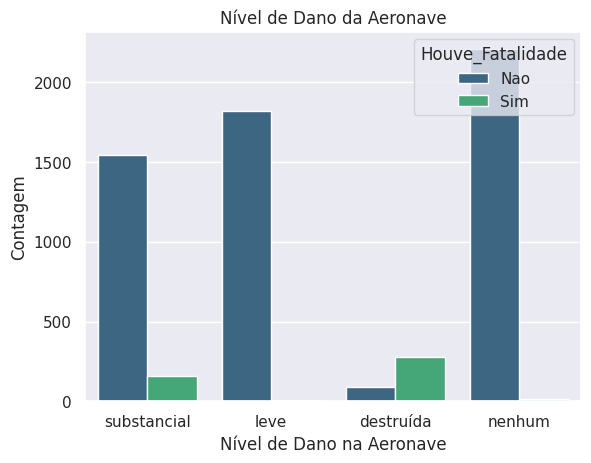

In [174]:
# Configurando o estilo do gráfico com Seaborn
sns.set_theme(style='darkgrid')

# Criando o gráfico de contagem
sns.countplot(x='Nivel de Dano da Aeronave', data=df, hue='Houve_Fatalidade', palette='viridis')

# Adicionando título e rótulos com o Matplotlib
plt.title('Nível de Dano da Aeronave')
plt.xlabel('Nível de Dano na Aeronave')
plt.ylabel('Contagem')

# Exibindo o gráfico
plt.show()


In [175]:
# Criando um dataset só com os acidentes que tiveram causas identificadas
df_causas = df[['Houve_Fatalidade','Fator do Acidente', 'Aspecto do Fator da Ocorrencia',
         'Fator Condicionante', 'Area do Fator']]

df_causas.head()

,Houve_Fatalidade,Fator do Acidente,Aspecto do Fator da Ocorrencia,Fator Condicionante,Area do Fator
0,Nao,aplicação de comandos,desempenho do ser humano,operação da aeronave,fator operacional
1,Nao,manutenção da aeronave,desempenho do ser humano,manutenção da aeronave,fator operacional
2,Sim,planejamento de voo,desempenho do ser humano,operação da aeronave,fator operacional
3,Sim,aplicação de comandos,desempenho do ser humano,operação da aeronave,fator operacional
4,Nao,condições meteorológicas adversas,elementos relacionados ao ambiente operacional,NaN,fator operacional


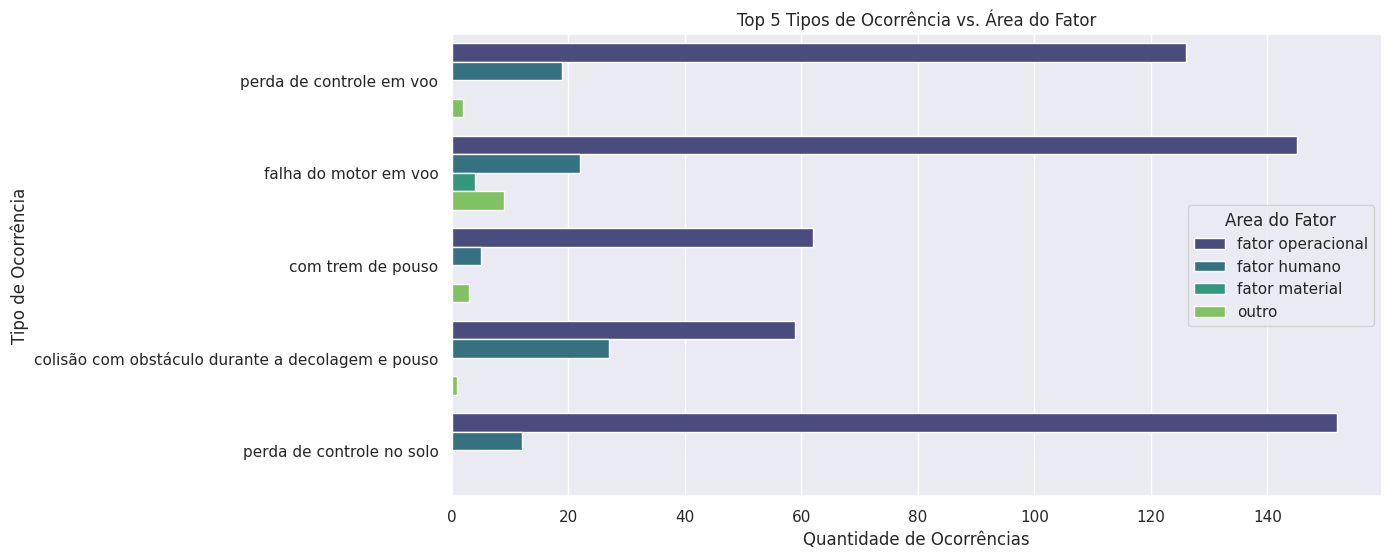

In [176]:
# 1. Descobrir quais são os 5 Tipos de Ocorrência mais comuns que possuem fatores preenchidos
top_tipos = df.dropna(subset=['Area do Fator'])['Tipo de Ocorrencia'].value_counts().head(5).index

# 2. Criar um filtro temporário só com esses Top 5
df_top_tipos = df[df['Tipo de Ocorrencia'].isin(top_tipos)]

# 3. Plotar o gráfico
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df_top_tipos,
    y='Tipo de Ocorrencia',
    hue='Area do Fator',
    palette='viridis'
)
plt.title('Top 5 Tipos de Ocorrência vs. Área do Fator')
plt.xlabel('Quantidade de Ocorrências')
plt.ylabel('Tipo de Ocorrência')
plt.show()

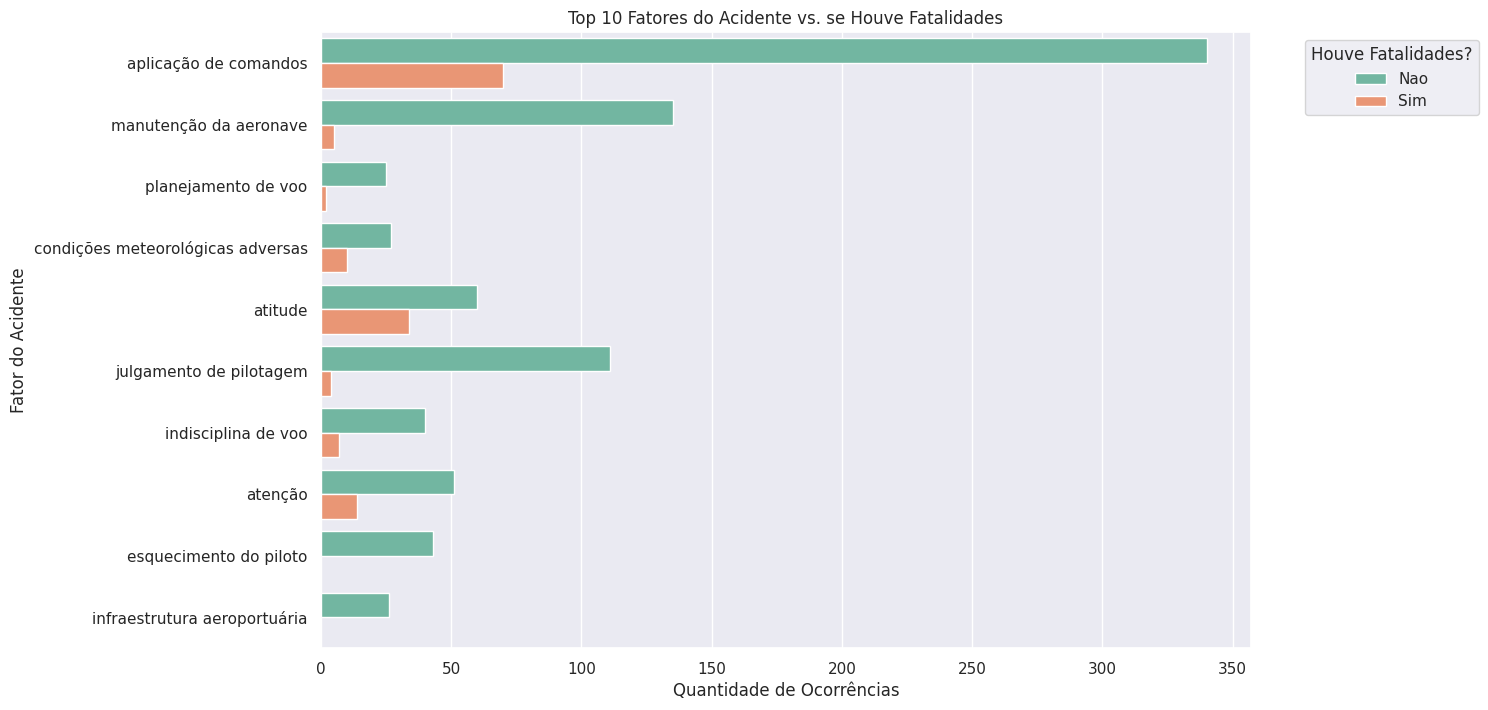

In [177]:
# 1. Identificar os 10 fatores mais frequentes (ignorando os valores nulos)
top_fatores = df.dropna(subset=['Fator do Acidente'])['Fator do Acidente'].value_counts().head(10).index

# 2. Criar um DataFrame temporário apenas com esses 10 fatores
df_top_fatores = df[df['Fator do Acidente'].isin(top_fatores)]

# 3. Gerar o gráfico
plt.figure(figsize=(12, 8))
sns.countplot(
    data=df_top_fatores,
    y='Fator do Acidente',
    hue='Houve_Fatalidade',
    palette='Set2'
)
plt.title('Top 10 Fatores do Acidente vs. se Houve Fatalidades')
plt.xlabel('Quantidade de Ocorrências')
plt.ylabel('Fator do Acidente')
# Move a legenda para não cobrir as barras
plt.legend(title='Houve Fatalidades?', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [178]:
# Obs.: estou mantendo as colunas: 'Fator do Acidente', 'Aspecto do Fator da Ocorrencia', 'Fator Condicionante' e 'Area do Fator'.
#  Porque elas vão ajudar a analisar as causas de acidentes aqui nas plotagens
df.dropna(subset=['Area do Fator'])['Area do Fator'].value_counts().head(10)


,count
Area do Fator,
fator operacional,888
fator humano,219
outro,20
fator material,13


Indica se o evento ocorreu durante uma excursão/saída não intencional de pista


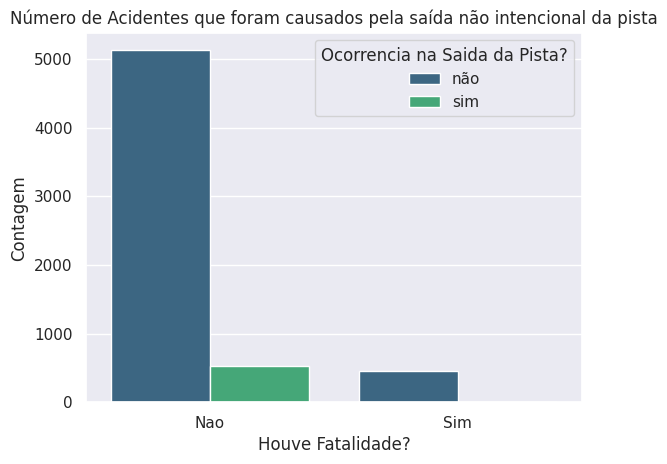


Só houve fatalidades em acidentes causados pela saída da pista


In [179]:
print(data_dictionary.loc['Ocorrencia na Saida da Pista?', 'Descricao'])

# Configurando o estilo do gráfico com Seaborn
sns.set_theme(style='darkgrid')

# Criando o gráfico de contagem
sns.countplot(x='Houve_Fatalidade', data=df, hue='Ocorrencia na Saida da Pista?', palette='viridis')

# Adicionando título e rótulos com o Matplotlib
plt.title('Número de Acidentes que foram causados pela saída não intencional da pista')
plt.xlabel('Houve Fatalidade?')
plt.ylabel('Contagem')

# Exibindo o gráfico
plt.show()

print('\nSó houve fatalidades em acidentes causados pela saída da pista')

In [180]:
# criando a coluna para a idade das aeronaves
df['Idade da Aeronave'] = 2026 - df['Ano de Fabricacao da Aeronave']

df_top_tipos = df[df['Tipo de Ocorrencia'].isin(top_tipos)]

In [181]:
df['Ano de Fabricacao da Aeronave'].max()

2020.0

/tmp/ipykernel_8930/1583689201.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


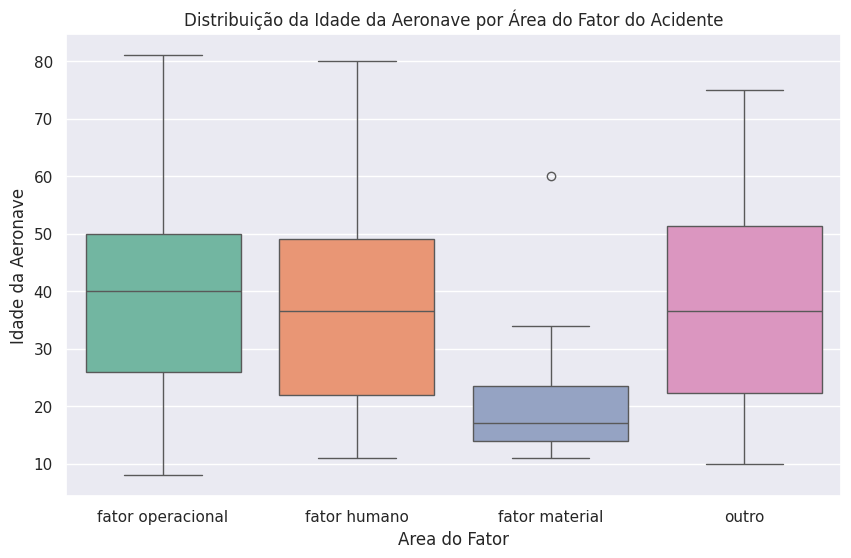


 As naves mais velhas sofreram mais com o fator humano/operacional do que com o fator material, como falta de manutenção


In [182]:
# Distribuição da Idade da Aeronave por Área do Fator

plt.figure(figsize=(10, 6))
# Removendo os nulos da Área do Fator só para este gráfico
sns.boxplot(
    data=df.dropna(subset=['Area do Fator']),
    x='Area do Fator',
    y='Idade da Aeronave',
    palette='Set2'
)
plt.title('Distribuição da Idade da Aeronave por Área do Fator do Acidente')
plt.show()

print('\n As naves mais velhas sofreram mais com o fator humano/operacional do que com o fator material, como falta de manutenção')

/tmp/ipykernel_8930/2797543227.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


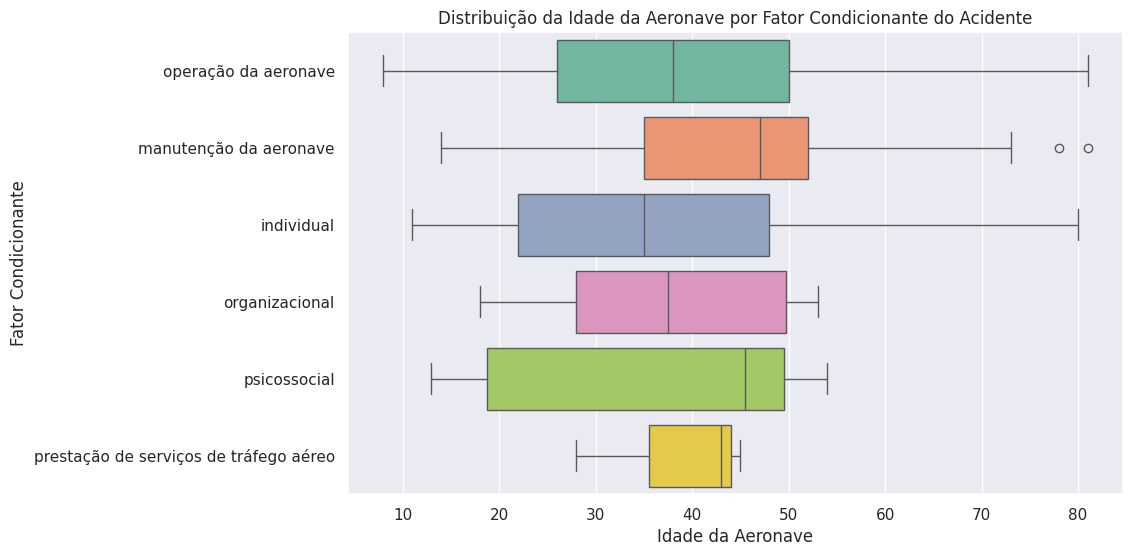


 O fator condicionante é um fator implícito no acidente.
Condição subjacente que levou à falha (Ex: Manutenção da Aeronave, Operação)


In [183]:
# Distribuição da Idade da Aeronave por Área do Fator

plt.figure(figsize=(10, 6))
# Removendo os nulos da Área do Fator só para este gráfico
sns.boxplot(
    data=df.dropna(subset=['Fator Condicionante']),
    x='Idade da Aeronave',
    y='Fator Condicionante',
    palette='Set2'
)
plt.title('Distribuição da Idade da Aeronave por Fator Condicionante do Acidente')
plt.show()

print('\n O fator condicionante é um fator implícito no acidente.')
print(data_dictionary.loc['Fator Condicionante', 'Descricao'])

In [184]:
df['Fator Condicionante'].value_counts()

,count
Fator Condicionante,
operação da aeronave,681
individual,167
manutenção da aeronave,140
organizacional,26
psicossocial,8
prestação de serviços de tráfego aéreo,4


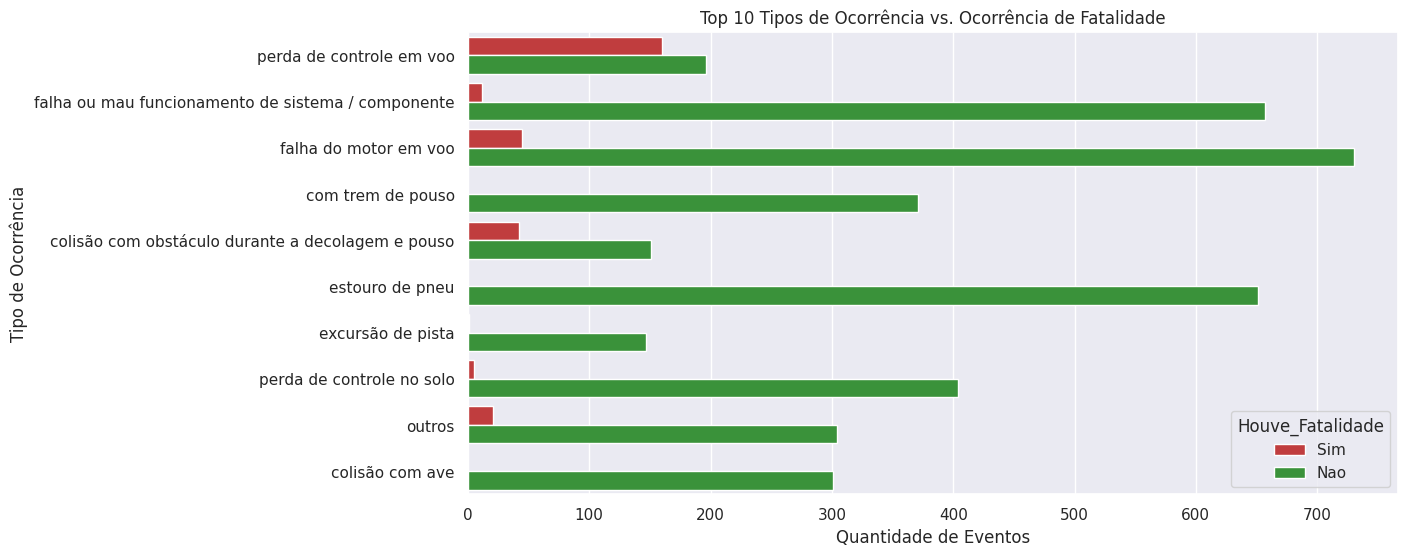

In [185]:
import seaborn as sns
import matplotlib.pyplot as plt

# Pega os 10 tipos de ocorrência mais frequentes no dataset inteiro
top_10_tipos = df['Tipo de Ocorrencia'].value_counts().head(10).index
df_top = df[df['Tipo de Ocorrencia'].isin(top_10_tipos)]

plt.figure(figsize=(12, 6))
sns.countplot(
    data=df_top,
    y='Tipo de Ocorrencia',
    hue='Houve_Fatalidade',
    palette={'Nao': '#2ca02c', 'Sim': '#d62728'} # Verde para Não, Vermelho para Sim
)
plt.title('Top 10 Tipos de Ocorrência vs. Ocorrência de Fatalidade')
plt.xlabel('Quantidade de Eventos')
plt.ylabel('Tipo de Ocorrência')
plt.show()

# 8)	Análise temporal dos acidentes

In [186]:
# Converte o texto para formato de data, avisando que o dia vem antes do mês
df['Data e Hora da Ocorrencia'] = pd.to_datetime(df['Data e Hora da Ocorrencia'], dayfirst=True, errors='coerce', format='mixed')

# Cria uma nova coluna só com o ano
df['Ano'] = df['Data e Hora da Ocorrencia'].dt.year

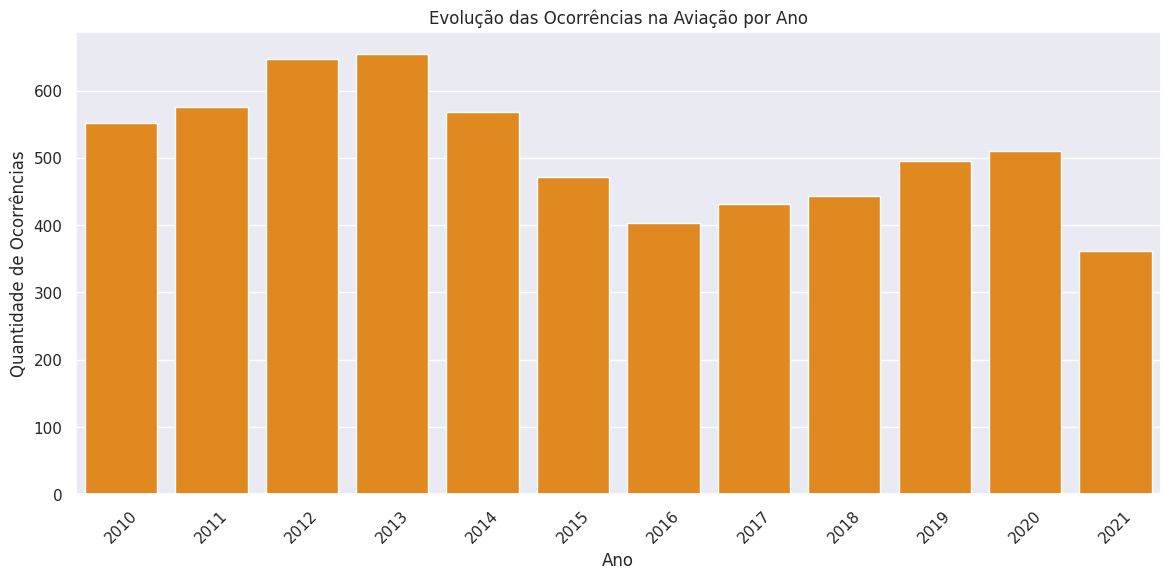

In [187]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

# O countplot vai contar quantos eventos aconteceram em cada ano
sns.countplot(
    data=df,
    x='Ano',
    color='darkorange'
)

plt.title('Evolução das Ocorrências na Aviação por Ano')
plt.xlabel('Ano')
plt.ylabel('Quantidade de Ocorrências')
plt.xticks(rotation=45) # Inclina os anos para não encavalarem

plt.show()

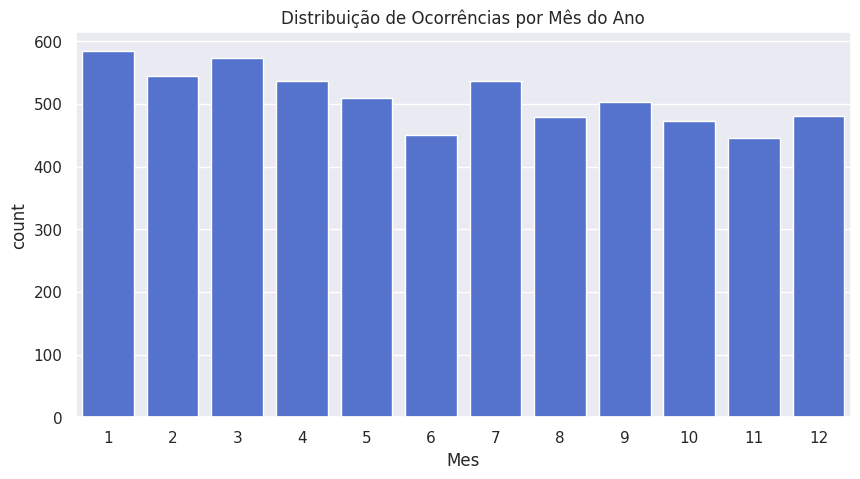

In [188]:
# Extrai o mês
df['Mes'] = df['Data e Hora da Ocorrencia'].dt.month

# Plota do mesmo jeito
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Mes', color='royalblue')
plt.title('Distribuição de Ocorrências por Mês do Ano')
plt.show()

/tmp/ipykernel_8930/433757463.py:3: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:royalblue'` for the same effect.

  sns.countplot(data=df, x='Mes', hue='Houve_Fatalidade', color='royalblue')


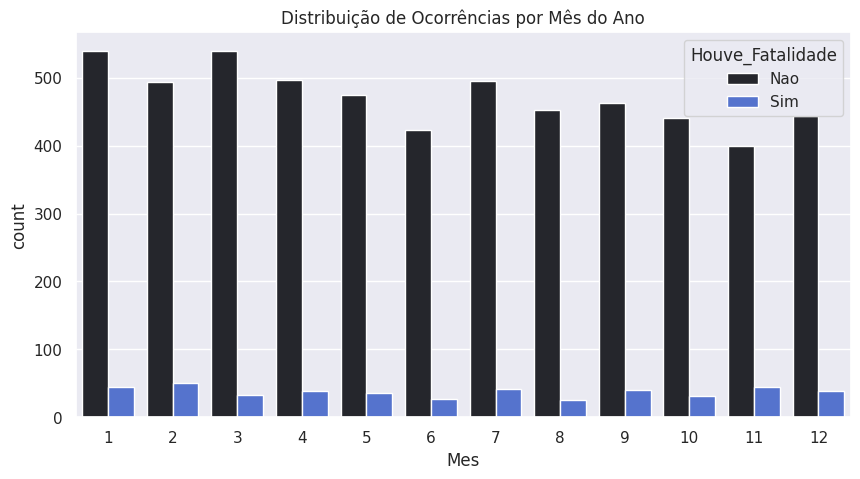

In [189]:
# mesmo gráfico, mas desta vez separando as colunas com a nossa variável das fatalidades
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='Mes', hue='Houve_Fatalidade', color='royalblue')
plt.title('Distribuição de Ocorrências por Mês do Ano')
plt.show()

# 9)	Análise de acidentes por região

In [190]:
data_dictionary.loc['UF da Ocorrencia', 'Descricao']

'Unidade Federativa (Estado) onde a ocorrência aconteceu'

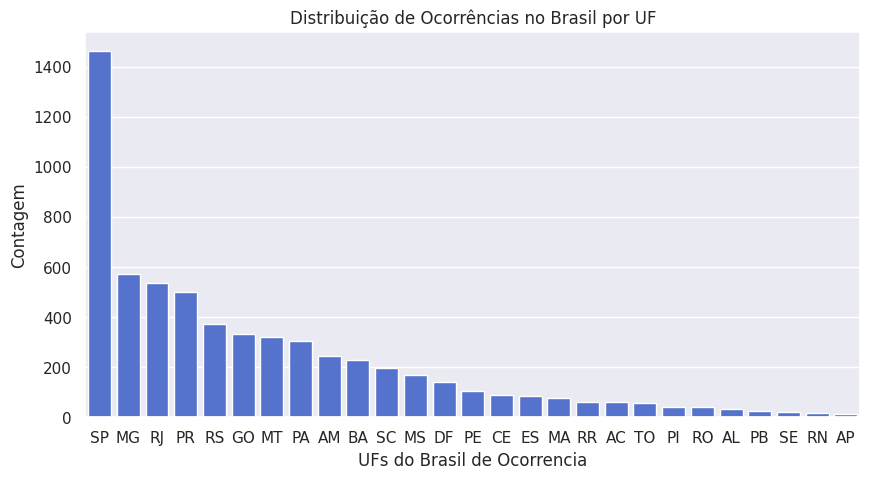

In [191]:
# salvando as UFs do Brasil e passando para upper case
# tambem estou removendo nesse caso o 'NAO INFORMADO' e o 'EXTERIOR'
UF_upper_case = df['UF da Ocorrencia'].str.upper()
UF_upper_case = UF_upper_case.replace('NAO INFORMADO', np.nan)
UF_upper_case = UF_upper_case.replace('EXTERIOR', np.nan)
df['UFs do Brasil de Ocorrencia'] = UF_upper_case

# criando uma contagem descresente para ordenar o plot
# com isso é possível fazer uma ordem descrescente
ordem_UF = df['UFs do Brasil de Ocorrencia'].value_counts().index

plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='UFs do Brasil de Ocorrencia', order=ordem_UF, color='royalblue')
plt.title('Distribuição de Ocorrências no Brasil por UF')
plt.ylabel('Contagem')
plt.show()

/tmp/ipykernel_8930/2641074607.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


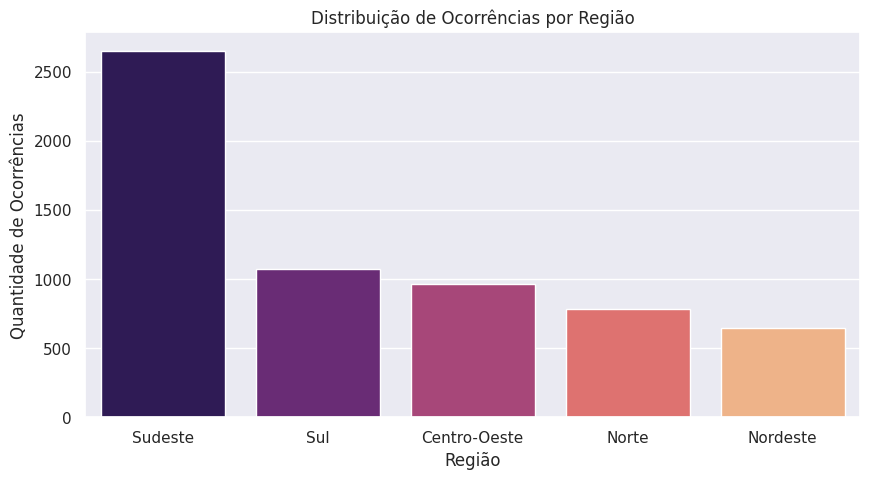

In [192]:
# Dicionário de mapeamento das regiões Brasileiras do IBGE
mapeamento_regioes = {
    # Norte
    'AC': 'Norte', 'AP': 'Norte', 'AM': 'Norte', 'PA': 'Norte', 'RO': 'Norte', 'RR': 'Norte', 'TO': 'Norte',
    # Nordeste
    'AL': 'Nordeste', 'BA': 'Nordeste', 'CE': 'Nordeste', 'MA': 'Nordeste', 'PB': 'Nordeste', 'PE': 'Nordeste', 'PI': 'Nordeste', 'RN': 'Nordeste', 'SE': 'Nordeste',
    # Centro-Oeste
    'DF': 'Centro-Oeste', 'GO': 'Centro-Oeste', 'MT': 'Centro-Oeste', 'MS': 'Centro-Oeste',
    # Sudeste
    'ES': 'Sudeste', 'MG': 'Sudeste', 'RJ': 'Sudeste', 'SP': 'Sudeste',
    # Sul
    'PR': 'Sul', 'RS': 'Sul', 'SC': 'Sul',
}

# 2. Criar a nova coluna 'Regiao'
nome_coluna_uf = 'UFs do Brasil de Ocorrencia'
df['Regiao'] = df[nome_coluna_uf].map(mapeamento_regioes)

# 3. Gerar o gráfico ordenado da região com mais acidentes para a com menos
plt.figure(figsize=(10, 5))

# Conta os valores para criar uma ordem decrescente no gráfico
ordem_regioes = df['Regiao'].value_counts().index

sns.countplot(
    data=df,
    x='Regiao',
    order=ordem_regioes,
    palette='magma'
)
plt.title('Distribuição de Ocorrências por Região')
plt.xlabel('Região')
plt.ylabel('Quantidade de Ocorrências')

plt.show()

A Região brasileira com mais acidentes foi a Sudeste!

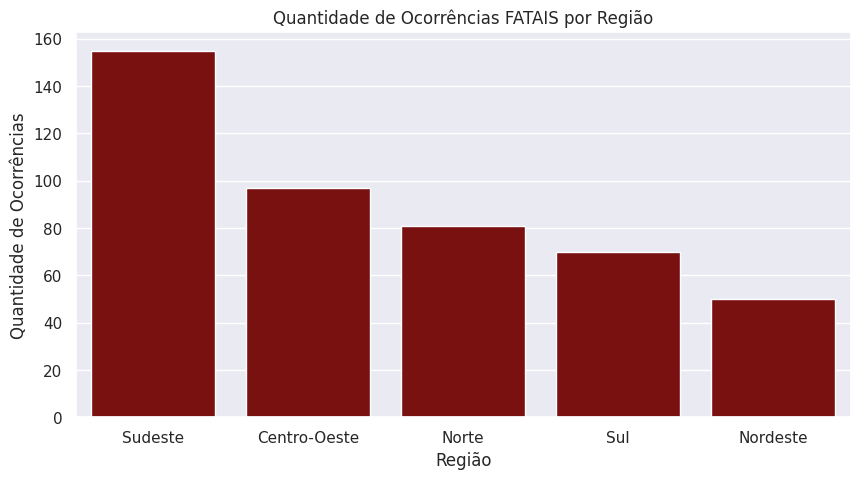

In [193]:
# criando um DataFrame auxiliar apenas com acidentes que foram fatais
df_fatais = df[df['Houve_Fatalidade'] == 'Sim']

# Conta os valores para criar uma ordem decrescente no gráfico
ordem_regioes = df_fatais['Regiao'].value_counts().index

# gráfico ordenado da região com mais acidentes fatais para a com menos
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_fatais,
    x='Regiao',
    order=ordem_regioes,
    color='darkred'
)
plt.title('Quantidade de Ocorrências FATAIS por Região')
plt.xlabel('Região')
plt.ylabel('Quantidade de Ocorrências')

plt.show()

A região Sudeste possui quase 160 acidentes fatais

# 10)	Correlação entre variáveis numéricas (se existirem)

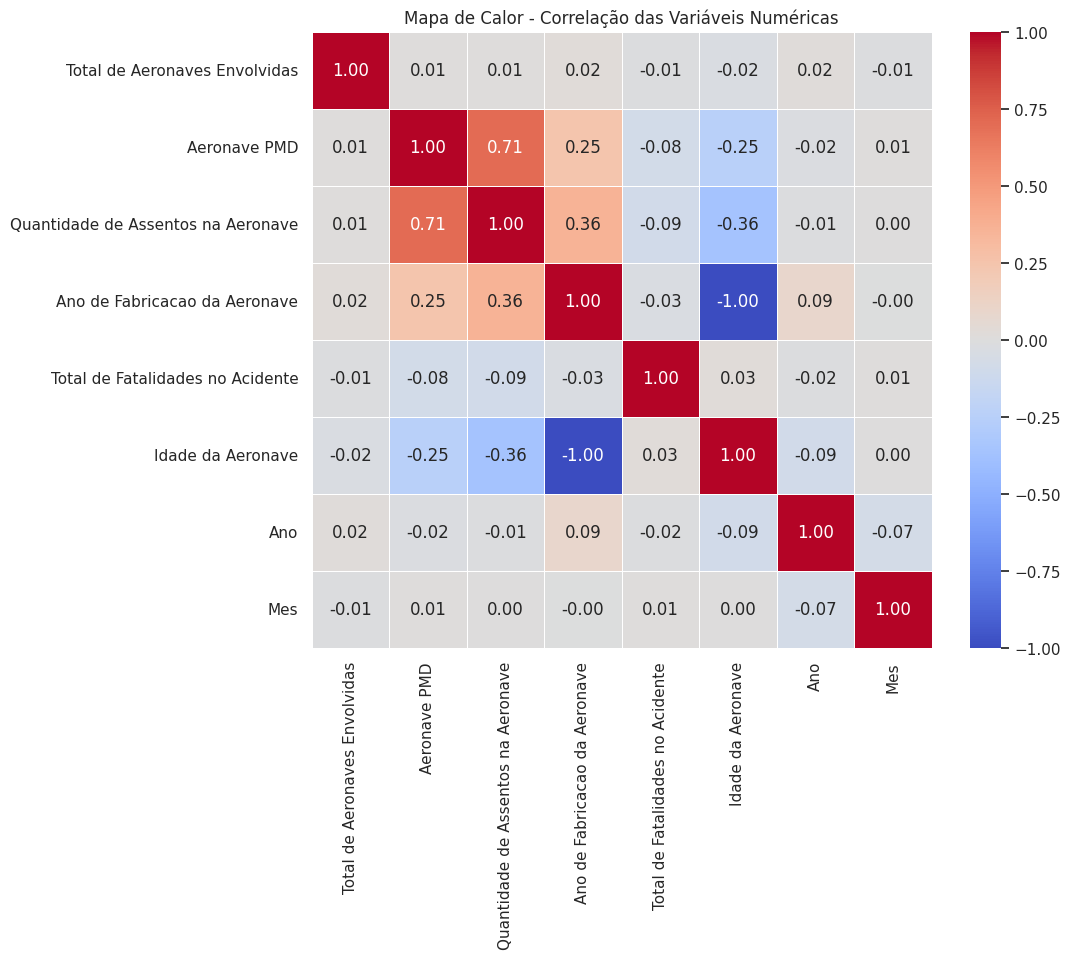

In [194]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

# 1. Seleciona apenas as colunas numéricas (int e float) e calcula a correlação
correlacao = df.select_dtypes(include=['number']).corr()

# 2. Plota o Heatmap
sns.heatmap(
    correlacao,
    annot=True,        # Mostra os números dentro dos quadrados
    cmap='coolwarm',   # Escala clássica: azul (negativo), branco (neutro), vermelho (positivo)
    fmt=".2f",         # Arredonda para 2 casas decimais
    linewidths=0.5
)

plt.title('Mapa de Calor - Correlação das Variáveis Numéricas')
plt.show()

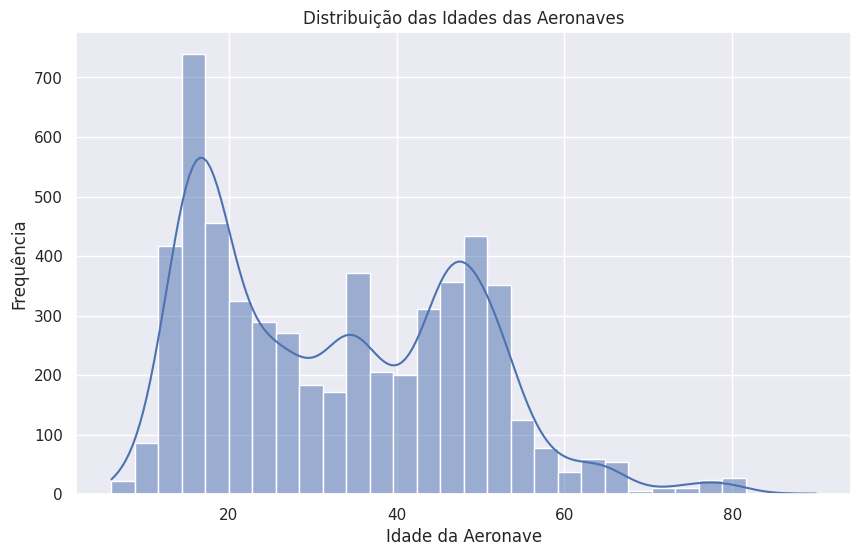

In [195]:
# Histograma da variável 'Idade da Aeronave'
plt.figure(figsize=(10, 6))
sns.histplot(df['Idade da Aeronave'], bins=30, kde=True)
plt.title('Distribuição das Idades das Aeronaves')
plt.xlabel('Idade da Aeronave')
plt.ylabel('Frequência')
plt.show()

/tmp/ipykernel_8930/1952048812.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.scatterplot(


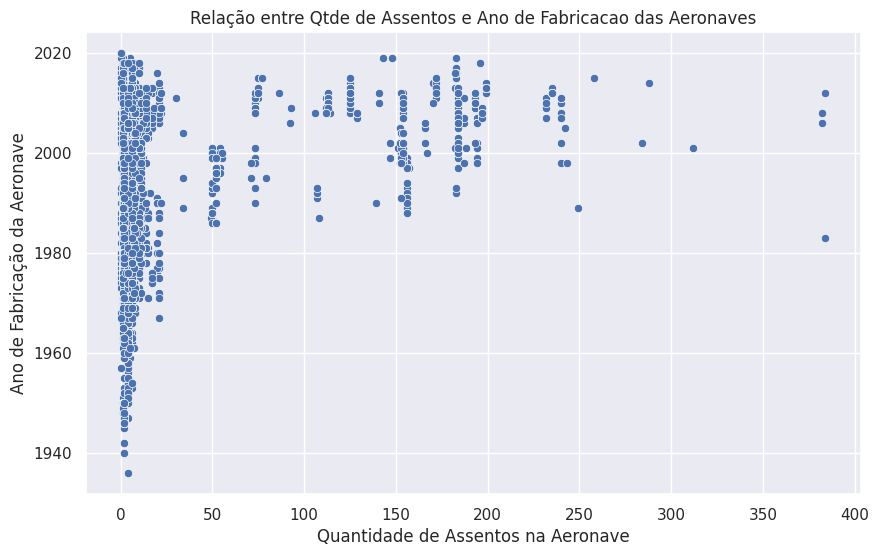

In [196]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x='Quantidade de Assentos na Aeronave',
    y='Ano de Fabricacao da Aeronave',
    palette='Set1'
)

plt.title('Relação entre Qtde de Assentos e Ano de Fabricacao das Aeronaves')
plt.xlabel('Quantidade de Assentos na Aeronave')
plt.ylabel('Ano de Fabricação da Aeronave')

plt.show()

Peso Máximo de Decolagem autorizado para a aeronave (em kg)
Capacidade máxima de passageiros e tripulantes


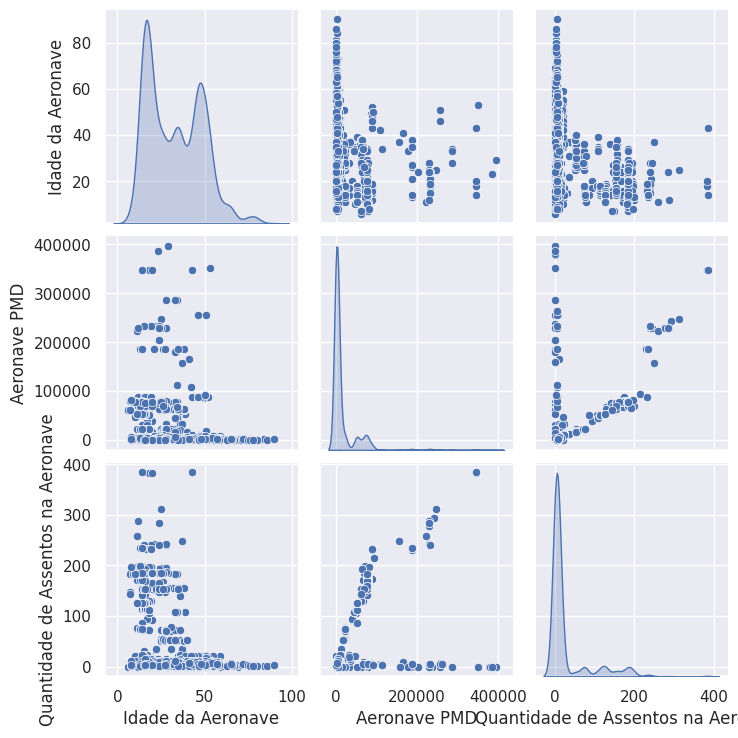

In [197]:
# Matriz de dispersão para variáveis numéricas

print(data_dictionary.loc['Aeronave PMD', 'Descricao'])
print(data_dictionary.loc['Quantidade de Assentos na Aeronave', 'Descricao'])

sns.pairplot(df[['Idade da Aeronave', 'Aeronave PMD', 'Quantidade de Assentos na Aeronave']], diag_kind='kde')
plt.show()

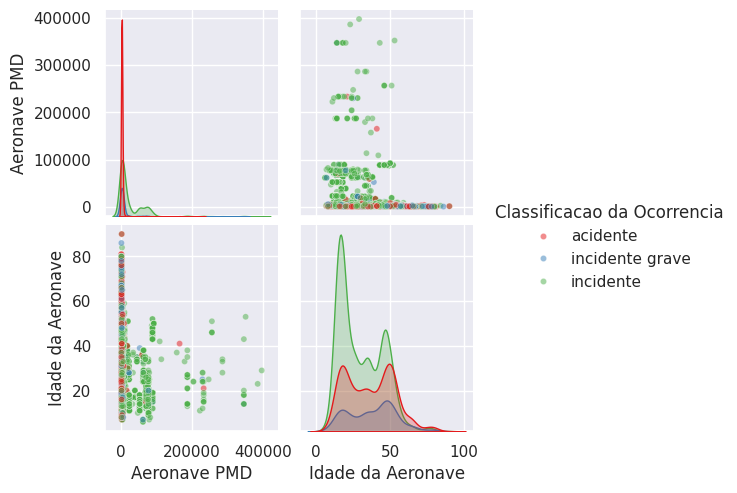

In [198]:
colunas_selecionadas = [
    'Aeronave PMD',
    'Idade da Aeronave',
    'Classificacao da Ocorrencia'
]

sns.pairplot(
    # O dropna garante que os nulos da idade não quebrem o gráfico
    df[colunas_selecionadas].dropna(),
    hue='Classificacao da Ocorrencia',
    palette='Set1',
    plot_kws={'alpha': 0.5, 's': 20} # 's' diminui o tamanho dos pontos para despoluir
)

plt.show()

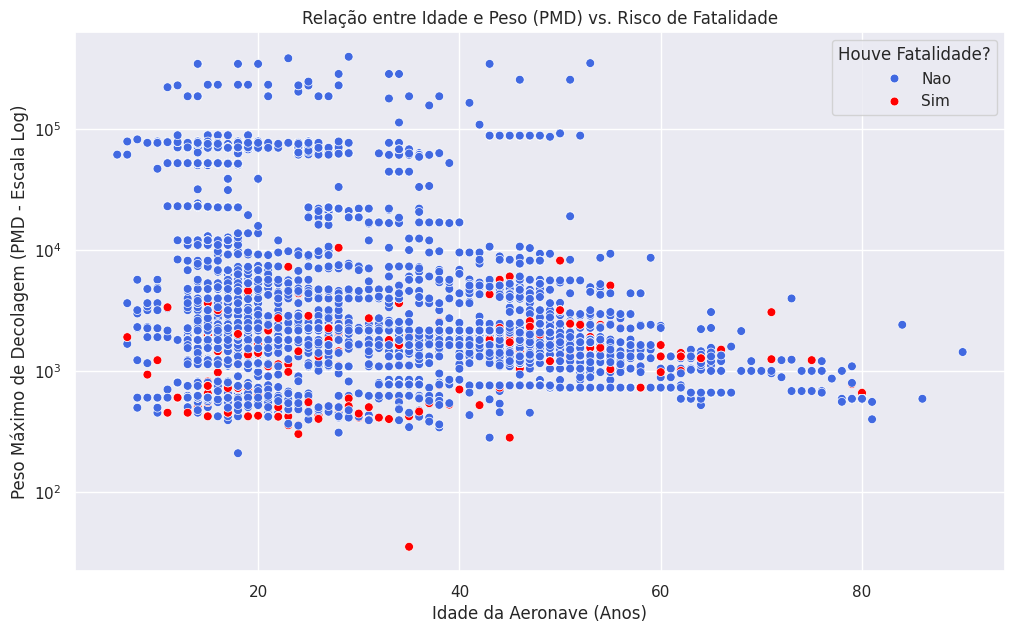

In [199]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=df,
    x='Idade da Aeronave',
    y='Aeronave PMD',
    hue='Houve_Fatalidade',
    s=40,
    palette={'Nao': 'royalblue', 'Sim': 'red'} # Destaca os fatais em vermelho
)

plt.yscale('log')
plt.title('Relação entre Idade e Peso (PMD) vs. Risco de Fatalidade')
plt.xlabel('Idade da Aeronave (Anos)')
plt.ylabel('Peso Máximo de Decolagem (PMD - Escala Log)')
plt.legend(title='Houve Fatalidade?')

plt.show()

# 11) Respostas das questões

In [200]:
top_10_acidentes = df['Tipo de Ocorrencia'].value_counts().head(12)

print('Porcentagem dos top 10 acidentes:')
for acidente in top_10_acidentes:
    porcentagem_do_total = (acidente / 6114) * 100
    print(porcentagem_do_total)

top_10_acidentes
# eu pulei os 'outros' e 'indeterminado'

Porcentagem dos top 10 acidentes:
12.675825973176316
10.942100098135427
10.647693817468106
6.689564932940792
6.068040562643114
5.8227019954203465
5.315668956493294
4.923127248936867
3.1566895649329405
2.4206738632646383
2.2407589139679422
2.060843964671246


,count
Tipo de Ocorrencia,
falha do motor em voo,775
falha ou mau funcionamento de sistema / componente,669
estouro de pneu,651
perda de controle no solo,409
com trem de pouso,371
perda de controle em voo,356
outros,325
colisão com ave,301
colisão com obstáculo durante a decolagem e pouso,193


In [201]:
df['Fator Condicionante'].value_counts()

,count
Fator Condicionante,
operação da aeronave,681
individual,167
manutenção da aeronave,140
organizacional,26
psicossocial,8
prestação de serviços de tráfego aéreo,4


In [202]:
df['Fator do Acidente'].value_counts().head(10)

,count
Fator do Acidente,
aplicação de comandos,410
manutenção da aeronave,140
julgamento de pilotagem,115
atitude,94
atenção,65
indisciplina de voo,47
esquecimento do piloto,43
condições meteorológicas adversas,37
planejamento de voo,27


Insights sobre os acidentes:
- O que os gráficos mostram?

Os gráficos mostram que houve mais acidentes fatais do que não fatais quando a aeronave foi destruída. Em qualquer outro nível de dano houve menos casos fatais do que os não fatais.

A região do Brasil que mais concentrou ocorrências (assim como as FATAIS) foi a região Sudeste.

Das aeronaves registradas, aquelas com uma idade próxima a 20 anos são as que aparecem com maior frequência.

A idade das aeronaves estão bem dispersas em relação ao Peso Máximo de Decolagem (PMD), e os riscos de fatalidade também estão. Isso pode significar que a idade das aeronaves não influencia tanto no risco de acidentes relacionados ao PMD das aeronaves.

- Quais são os tipos de acidentes mais comuns?

Dos 81 tipos de acidente, os 10 mais comuns foram:
1. falha do motor em voo (12,6% do total)
2. falha ou mau funcionamento de sistema / componente (10,9%)
3. estouro de pneu (10,6%)
4. perda de controle no solo (6,7%)
5. com trem de pouso (6,1%)
6. perda de controle em voo (5,8%)
7. colisão com ave (4,9%)
8. colisão com obstáculo durante a decolagem e pouso (3,2%)
9. excursão de pista (2,4%)
10. tráfego aéreo (2,1%)

Os demais acidentes representaram 34,7% do total

Além disso, o acidente que mais registrou fatalidades foi a perda de controle em voo, segundo o gráfico 'Top 10 Tipos de Ocorrência vs. Ocorrência de Fatalidade'.

- Quais são as principais causas?

Os principais fatores condicionantes (os 3 com mais frequência) foram a operação da aeronave, fatores individuais e manutenção da aeronave.

Isso está coerente, pois entre os tipos de acidente que mais ocorreram estão a falha do motor em voo, falha ou mau funcionamento de sistema/componente, estouro de pneu, perda de controle no voo/solo, etc.

Por outro lado, os principais fatores causadores do acidente registrados foram:
1. aplicação de comandos
2. falta de manutenção na aeronave
3. planejamento de voo
4. condições meteorológicas adversas
5. atitude
6. julgamento de pilotagem
7. indisciplina de voo
8. atenção
9. esquecimento do piloto
10. infraestrutura aeroportuária

Portanto, com essas informações, é possível concluir que fatores humanos também tiveram um grande impacto no acontecimento desses acidentes.

Tendências temporais:
- Existe uma tendência de aumento ou diminuição de acidentes ao longo dos anos?

De 2010 até 2013 houve um aumento no número de acidentes.

De 2013 até 2016 houve uma queda, porém o número voltou a crescer até 2020.

De 2020 para 2021 houve mais uma diminuição

Fatores geográficos:
- Quais regiões têm mais acidentes?

As 3 regiões do Brasil com mais acidentes foram Sudeste, Sul e Centro-Oeste.

Outro ponto que vale ressaltar é que as 3 regiões do Brasil com mais acidentes FATAIS foram Sudeste, Centro-Oeste e Norte

# 12) Questões da Aula de Probabilidade e Inferência, com testes de Hipóteses

1.	Suponha que o peso médio dos Pinguins Reis encontrados em uma colônia na Antártica no último ano foi 15,4 kg. Em uma amostra de 35 pinguins na mesma época neste ano, na mesma colônia, o peso médio foi 14,1 kg. Assuma que o desvio padrão da população seja 2 kg. A um nível de significância de 5%, nós podemos rejeitar a hipótese nula de que o peso médio dos pinguins não difere do último ano?

H0: mu = 15,4 kg

H1: mu != 15,4 kg

alpha (nível de significância) = 5% = 0,05

Regra: se p-valor for menor que o nível de significância, rejeitamos H0.

- Portanto, há evidências, ao nível de significância de 5%, de que, o peso médio dos pinguins se difere do último ano.


In [203]:
import numpy as np
from scipy.stats import norm

# Definir os parâmetros
xbar = 14.1          # Média amostral
mu0 = 15.4           # Média sob a hipótese nula
var = 4              # Variância
sigma = 2            # Desvio padrão
n = 35               # Tamanho da amostra

# Calcular o valor de z
z = (xbar - mu0) / (sigma / np.sqrt(n))

# Calcular o valor-p
p = 2 * norm.cdf(-abs(z))

# Mostrar os resultados
print(f"Valor de z: {z:.4f}")
print(f"Valor-p: {p:.4f}")

Valor de z: -3.8455
Valor-p: 0.0001


2.	Na indústria cerâmica, avalia-se sistematicamente a resistência de amostras de massas cerâmicas, após o processo de queima. Dessas avaliações, sabe-se que certo tipo de massa tem resistência mecânica aproximadamente normal, com média 53 MPa e variância 16 MPa². Após a troca de alguns fornecedores de matérias-primas, deseja-se verificar se houve alteração na qualidade. Uma amostra de 15 corpos de prova de massa cerâmica acusou média igual a 50 MPa. Qual é a conclusão ao nível de significância de 5 %?

H0: mu = 53 MPa

H1: mu != 53 MPa

alpha (nível de significância) = 5% = 0,05

Regra: se p-valor for menor que o nível de significância, rejeitamos H0.

- Portanto, há evidências, ao nível de significância de 5%, de que, houve alteração na qualidade pois a média da resistência mecânica da massa se difere de 53 MPa.

In [204]:
import numpy as np
from scipy.stats import norm

# Definir os parâmetros
xbar = 50          # Média amostral
mu0 = 53           # Média sob a hipótese nula
var = 16           # Variância
sigma = np.sqrt(var)  # Desvio padrão
n = 15           # Tamanho da amostra

# Calcular o valor de z
z = (xbar - mu0) / (sigma / np.sqrt(n))

# Calcular o valor-p
p = 2 * norm.cdf(-abs(z))

# Mostrar os resultados
print(f"Valor de z: {z:.4f}")
print(f"Valor-p: {p:.4f}")

Valor de z: -2.9047
Valor-p: 0.0037


# 12) Análise Exploratória de Dados na base Diamonds

In [205]:
pip install seaborn pandas matplotlib numpy

In [206]:
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [207]:
# carregando o dataset diamonds
diamonds = sns.load_dataset('diamonds')

In [208]:
diamonds.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [209]:
diamonds.shape

(53940, 10)

In [210]:
diamonds.dtypes

,0
carat,float64
cut,category
color,category
clarity,category
depth,float64
table,float64
price,int64
x,float64
y,float64
z,float64


In [211]:
diamonds.describe()
# não podemos ter x, y ou z como zero!

,carat,depth,table,price,x,y,z
count,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000,53940.000000
mean,0.797940,61.749405,57.457184,3932.799722,5.731157,5.734526,3.538734
std,0.474011,1.432621,2.234491,3989.439738,1.121761,1.142135,0.705699
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,950.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2401.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5324.250000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [212]:
diamonds.duplicated().sum()

np.int64(146)

In [213]:
diamonds.drop_duplicates(inplace=True)
diamonds.shape

(53794, 10)

In [214]:
diamonds.isnull().sum()

,0
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
price,0
x,0
y,0
z,0


In [215]:
# reduzindo a granularidade dos dados (convertendo o x, y e z em volume p/ reduzir o número de colunas)
diamonds['volume'] = diamonds['x'] * diamonds['y'] * diamonds['z']

diamonds.drop(columns=['x', 'y', 'z'], inplace=True)

diamonds.head()

,carat,cut,color,clarity,depth,table,price,volume
0,0.23,Ideal,E,SI2,61.5,55.0,326,38.202030
1,0.21,Premium,E,SI1,59.8,61.0,326,34.505856
2,0.23,Good,E,VS1,56.9,65.0,327,38.076885
3,0.29,Premium,I,VS2,62.4,58.0,334,46.724580
4,0.31,Good,J,SI2,63.3,58.0,335,51.917250


In [216]:
# criando um dicionário para os dados
dicionario_diamonds = pd.DataFrame([
    {'Variavel': 'carat', 'Descricao': 'Peso do diamante em quilates (numérica contínua).'},
    {'Variavel': 'cut', 'Descricao': 'Qualidade do corte. Ordem (pior p/ melhor): Fair, Good, Very Good, Premium, Ideal (categórica ordinal).'},
    {'Variavel': 'color', 'Descricao': 'Cor do diamante. Ordem (pior p/ melhor): J, I, H, G, F, E, D (categórica ordinal).'},
    {'Variavel': 'clarity', 'Descricao': 'Pureza/Clareza. Ordem (pior p/ melhor): I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF (categórica ordinal).'},
    {'Variavel': 'depth', 'Descricao': 'Porcentagem de profundidade total (z / média(x, y)) (numérica contínua).'},
    {'Variavel': 'table', 'Descricao': 'Largura do topo do diamante em relação ao ponto mais largo (numérica contínua).'},
    {'Variavel': 'price', 'Descricao': 'Preço em dólares americanos (numérica contínua - Variável Alvo).'},
    {'Variavel': 'volume', 'Descricao': 'Volume estimado do diamante em mm³ (x * y * z) (numérica contínua).'}
]).set_index('Variavel')


lista_colunas = diamonds.columns.to_list()

for coluna in lista_colunas:
  dicionario_diamonds.loc[dicionario_diamonds.index == coluna, 'Tipo de Dado'] = diamonds[coluna].dtype

display(dicionario_diamonds)

,Descricao,Tipo de Dado
Variavel,,
carat,Peso do diamante em quilates (numérica contínua).,float64
cut,Qualidade do corte. Ordem (pior p/ melhor): Fa...,category
color,"Cor do diamante. Ordem (pior p/ melhor): J, I,...",category
clarity,"Pureza/Clareza. Ordem (pior p/ melhor): I1, SI...",category
depth,Porcentagem de profundidade total (z / média(x...,float64
table,Largura do topo do diamante em relação ao pont...,float64
price,Preço em dólares americanos (numérica contínua...,int64
volume,Volume estimado do diamante em mm³ (x * y * z)...,float64


In [217]:
diamonds['volume'].describe()
# não podemos ter volumes nulos!

,volume
count,53794.000000
mean,129.826975
std,78.160819
min,0.000000
25%,65.190168
50%,114.840180
75%,170.823600
max,3840.598060


In [218]:
# Contando diamantes com erro de dimensão
diamantes_zerados = diamonds[(diamonds['volume'] == 0)]
print(f"Diamantes com dimensão zero: {len(diamantes_zerados)}")

# Removendo essas anomalias da base
diamonds = diamonds[diamonds['volume'] > 0]

diamonds['volume'].describe()

Diamantes com dimensão zero: 19


,volume
count,53775.000000
mean,129.872846
std,78.136513
min,31.707984
25%,65.214611
50%,114.852720
75%,170.839422
max,3840.598060


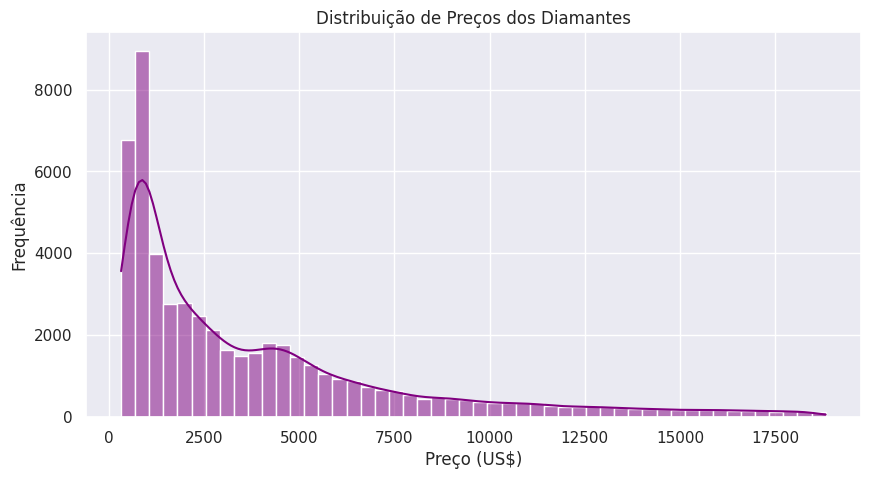

In [219]:
# plotando um histograma da variavel 'price'
plt.figure(figsize=(10, 5))
sns.histplot(diamonds['price'], bins=50, kde=True, color='purple')
plt.title('Distribuição de Preços dos Diamantes')
plt.xlabel('Preço (US$)')
plt.ylabel('Frequência')
plt.show()

A distribuição é fortemente assimétrica à direita (right-skewed), o que significa que o uso da mediana é muito mais seguro que a média para análises de preço.

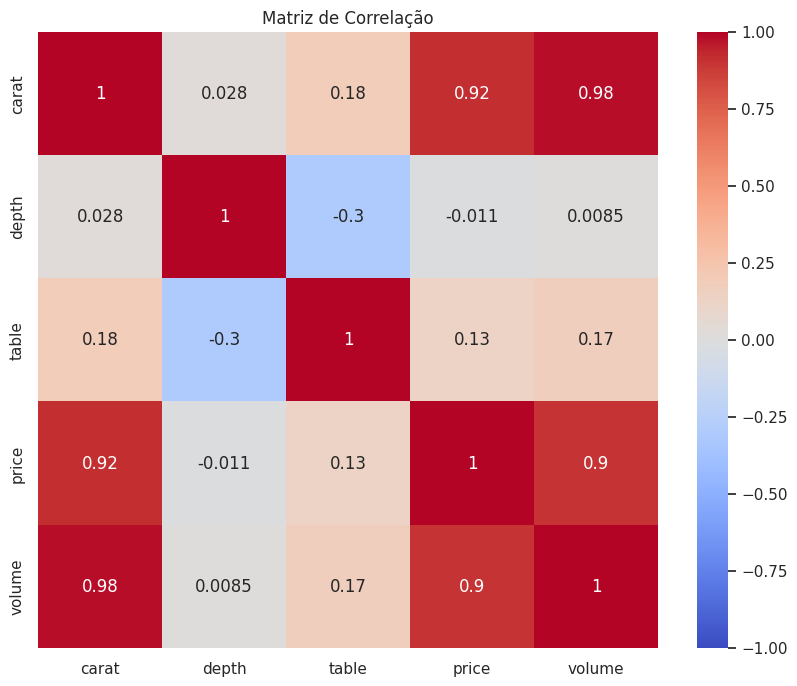

In [220]:
# Calcular e visualizar a matriz de correlação
plt.figure(figsize=(10, 8))
corr = diamonds[['carat', 'depth', 'table', 'price', 'volume']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Matriz de Correlação')
plt.show()


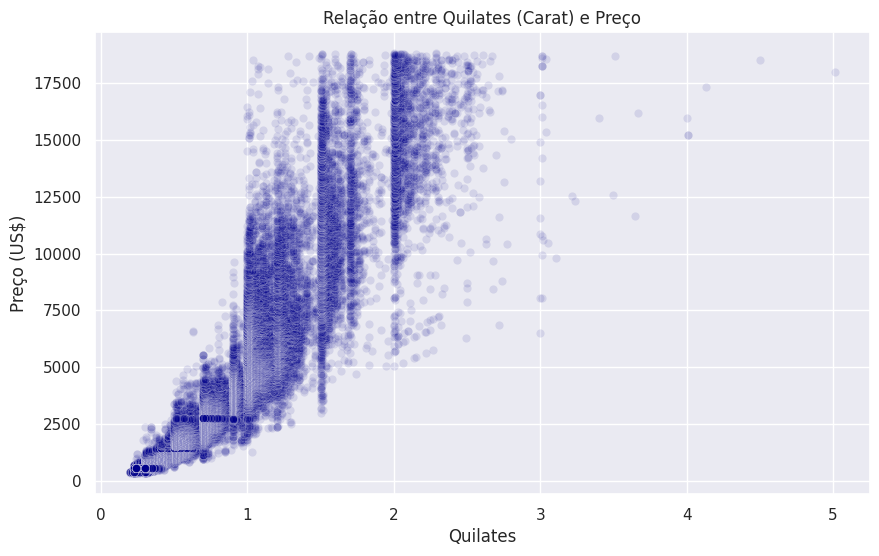

In [221]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=diamonds, x='carat', y='price', alpha=0.1, color='darkblue')
plt.title('Relação entre Quilates (Carat) e Preço')
plt.xlabel('Quilates')
plt.ylabel('Preço (US$)')
plt.show()

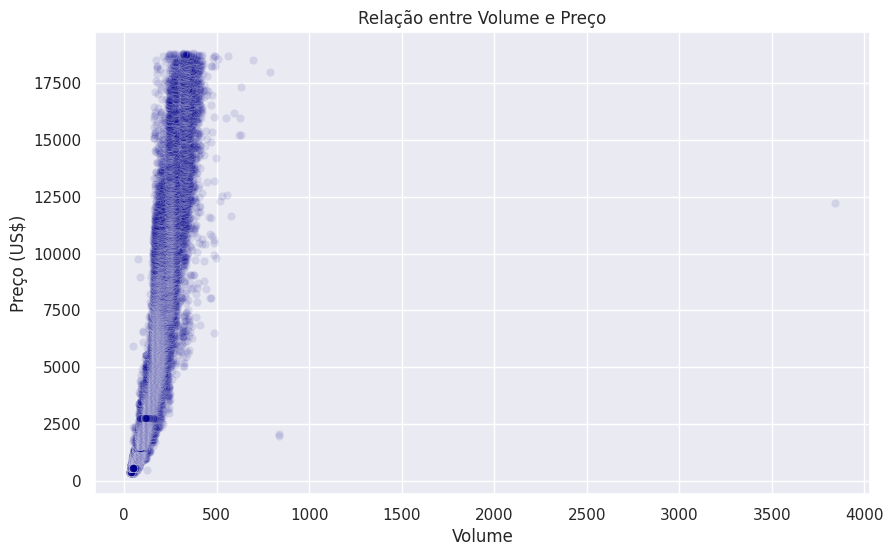

In [222]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=diamonds, x='volume', y='price', alpha=0.1, color='darkblue')
plt.title('Relação entre Volume e Preço')
plt.xlabel('Volume')
plt.ylabel('Preço (US$)')
plt.show()

/tmp/ipykernel_8930/2408350589.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=diamonds, x='cut', y='price', order=ordem_corte, palette='viridis')


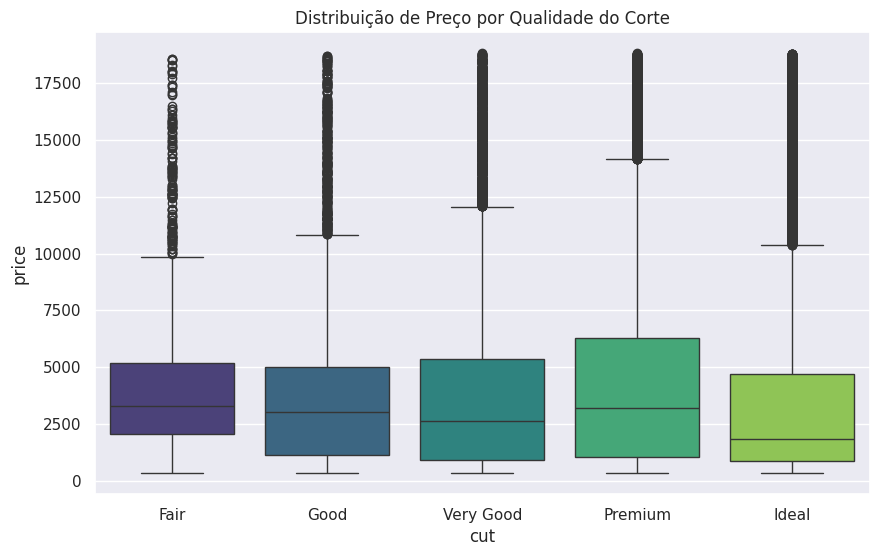

In [223]:
plt.figure(figsize=(10, 6))
# A ordem garante que o gráfico vá do pior para o melhor corte
ordem_corte = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
sns.boxplot(data=diamonds, x='cut', y='price', order=ordem_corte, palette='viridis')
plt.title('Distribuição de Preço por Qualidade do Corte')
plt.show()

os cortes "Ideais" (os melhores) parecem ter um preço mediano menor do que os cortes "Fair" (os piores).

Isso acontece porque diamantes com corte "Ideal" tendem a ser muito menores (baixo carat) do que os de corte "Fair". O tamanho (carat) domina o preço, mascarando a qualidade do corte quando olhamos apenas duas variáveis.